# NF-CSE-CIC-IDS2018-v3 — Data understanding

**Owner:** Ahmed Hamouda  
**Goal of this notebook:** understand the dataset and find its quality problems. For each problem we
take a decision on how it will be solved. The data is **not changed** here: the solutions are applied
later, once the team has agreed on them.

**Size:** 20,115,529 flows (4.2 GB CSV). The checks are the same as for UNSW (`01_unsw.ipynb`), so the two datasets can be compared problem by problem.

## Step 0 — Initial inspection *(lab 2.1)*
- Load the dataset and describe its structure
- Data type of each column
- Number of rows and columns
- Obvious quality issues from the first look

### 0.1 Load the data

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.csv as pv
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import *

pd.set_option("display.max_columns", 100)

SOURCE = "CIC18"
path = RAW_DIR / DATASETS[SOURCE]["file"]

# 20 million rows: integer columns are read as int32 instead of int64, which halves the memory.
# Every value fits (pyarrow stops with an error if one does not); only the timestamps need int64.
header = pd.read_csv(path, nrows=0).columns
types = {c: pa.int32() for c in header if c not in ["IPV4_SRC_ADDR", "IPV4_DST_ADDR", "Attack"]}
types["FLOW_START_MILLISECONDS"] = types["FLOW_END_MILLISECONDS"] = pa.int64()
table = pv.read_csv(path, convert_options=pv.ConvertOptions(column_types=types))
df = table.to_pandas(self_destruct=True)
del table

print("rows:", len(df), "(official: 20,115,529)")
print("columns:", df.shape[1])
print(f"memory: {df.memory_usage(deep=True).sum() / 1e9:.1f} GB")

rows: 20115529 (official: 20,115,529)
columns: 55
memory: 5.5 GB


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20115529 entries, 0 to 20115528
Data columns (total 55 columns):
 #   Column                       Dtype
---  ------                       -----
 0   FLOW_START_MILLISECONDS      int64
 1   FLOW_END_MILLISECONDS        int64
 2   IPV4_SRC_ADDR                str  
 3   L4_SRC_PORT                  int32
 4   IPV4_DST_ADDR                str  
 5   L4_DST_PORT                  int32
 6   PROTOCOL                     int32
 7   L7_PROTO                     int32
 8   IN_BYTES                     int32
 9   IN_PKTS                      int32
 10  OUT_BYTES                    int32
 11  OUT_PKTS                     int32
 12  TCP_FLAGS                    int32
 13  CLIENT_TCP_FLAGS             int32
 14  SERVER_TCP_FLAGS             int32
 15  FLOW_DURATION_MILLISECONDS   int32
 16  DURATION_IN                  int32
 17  DURATION_OUT                 int32
 18  MIN_TTL                      int32
 19  MAX_TTL                      int32
 20  LONGEST_FLO

### 0.2 What the data looks like
The first flows, then summary statistics for every numeric column.

In [3]:
df.head()

,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,TCP_FLAGS,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,FLOW_DURATION_MILLISECONDS,DURATION_IN,DURATION_OUT,MIN_TTL,MAX_TTL,LONGEST_FLOW_PKT,SHORTEST_FLOW_PKT,MIN_IP_PKT_LEN,MAX_IP_PKT_LEN,SRC_TO_DST_SECOND_BYTES,DST_TO_SRC_SECOND_BYTES,RETRANSMITTED_IN_BYTES,RETRANSMITTED_IN_PKTS,RETRANSMITTED_OUT_BYTES,RETRANSMITTED_OUT_PKTS,SRC_TO_DST_AVG_THROUGHPUT,DST_TO_SRC_AVG_THROUGHPUT,NUM_PKTS_UP_TO_128_BYTES,NUM_PKTS_128_TO_256_BYTES,NUM_PKTS_256_TO_512_BYTES,NUM_PKTS_512_TO_1024_BYTES,NUM_PKTS_1024_TO_1514_BYTES,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_STDDEV,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV,Label,Attack
0,1518611287705,1518611287705,172.31.0.2,53,172.31.66.58,63593,17,5,156,1,0,0,0,0,0,1,0,0,0,0,156,156,0,156,0,1,0,0,0,0,1248000,0,0,1,0,0,0,0,0,0,0,45856,1,60,0,0,0,0,0,0,0,0,0,0,Benign
1,1518611287743,1518611290747,172.31.66.58,56163,239.255.255.250,1900,17,12,805,5,0,0,0,0,0,3003,3003,0,1,1,161,161,0,161,0,0,0,0,0,0,2143,0,0,5,0,0,0,0,0,0,0,0,0,0,0,0,2793,750,1182,0,0,0,0,0,Benign
2,1518611288143,1518611300202,172.31.66.46,62388,239.255.255.250,1900,17,12,1288,8,0,0,0,0,0,12058,12058,0,1,1,161,161,0,161,0,0,0,0,0,0,854,0,0,8,0,0,0,0,0,0,0,0,0,0,0,0,3016,1722,1436,0,0,0,0,0,Benign
3,1518611288165,1518611336194,0.0.0.0,546,0.0.0.0,547,17,103,393,3,0,0,0,0,0,48029,48029,0,1,1,131,131,0,131,0,0,0,0,0,0,65,0,0,3,0,0,0,0,0,0,0,0,0,0,0,16014,32014,24014,8000,0,0,0,0,0,Benign
4,1518611288175,1518611288176,172.31.66.46,49187,169.254.169.254,80,6,7,373,5,700,5,27,27,27,1,0,0,128,128,528,40,40,528,700,373,0,0,0,0,1492000,2800000,8,1,0,1,0,8192,17922,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Benign


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
FLOW_START_MILLISECONDS,20115529.0,1.519309e+12,4.679144e+08,1.518611e+12,1.518804e+12,1.519247e+12,1.519835e+12,1.520021e+12
FLOW_END_MILLISECONDS,20115529.0,1.519309e+12,4.679141e+08,1.518611e+12,1.518804e+12,1.519247e+12,1.519835e+12,1.520021e+12
L4_SRC_PORT,20115529.0,5.009062e+04,1.548064e+04,0.000000e+00,5.024400e+04,5.326000e+04,5.878500e+04,6.553500e+04
L4_DST_PORT,20115529.0,2.527545e+03,8.251328e+03,0.000000e+00,5.300000e+01,8.000000e+01,4.450000e+02,6.553500e+04
PROTOCOL,20115529.0,1.024936e+01,5.554124e+00,1.000000e+00,6.000000e+00,6.000000e+00,1.700000e+01,5.800000e+01
L7_PROTO,20115529.0,3.830512e+01,4.343755e+01,0.000000e+00,5.000000e+00,7.000000e+00,8.800000e+01,4.010000e+02
IN_BYTES,20115529.0,2.295718e+03,1.090547e+05,2.800000e+01,6.700000e+01,1.460000e+02,1.120000e+03,1.859742e+07
IN_PKTS,20115529.0,3.132480e+01,1.772182e+03,1.000000e+00,1.000000e+00,3.000000e+00,8.000000e+00,3.099570e+05
OUT_BYTES,20115529.0,5.363537e+03,2.653292e+05,0.000000e+00,9.200000e+01,1.920000e+02,1.721000e+03,1.664690e+08
OUT_PKTS,20115529.0,8.010206e+00,1.817949e+02,0.000000e+00,1.000000e+00,2.000000e+00,7.000000e+00,1.231170e+05


### 0.3 Feature dictionary
Every column with its official description (from `NetFlow_v3_Features.csv`), type, number of distinct values and an example value.

In [5]:
features = pd.read_csv(RAW_DIR / "NetFlow_v3_Features.csv")
features["Feature"] = features["Feature"].str.strip()

dictionary = pd.DataFrame({
    "description": df.columns.map(features.set_index("Feature")["Description"]),
    "dtype": df.dtypes.astype(str).values,
    "distinct": df.nunique().values,
    "example": df.iloc[0].values,
}, index=df.columns)
dictionary

,description,dtype,distinct,example
FLOW_START_MILLISECONDS,Flow start timestamp in milliseconds,int64,15843427,1518611287705
FLOW_END_MILLISECONDS,Flow end timestamp in milliseconds,int64,16095331,1518611287705
IPV4_SRC_ADDR,IPv4 source address,str,181876,172.31.0.2
L4_SRC_PORT,IPv4 source port number,int32,65319,53
IPV4_DST_ADDR,IPv4 destination address,str,29036,172.31.66.58
L4_DST_PORT,IPv4 destination port number,int32,63307,63593
PROTOCOL,IP protocol identifier byte,int32,6,17
L7_PROTO,Layer 7 protocol (numeric),int32,149,5
IN_BYTES,Incoming number of bytes,int32,37794,156
IN_PKTS,Incoming number of packets,int32,5751,1


### 0.4 Same columns as UNSW?
The four NetFlow datasets are merged later, so they must have the same columns, in the same order and with
compatible types. Types are inferred by pyarrow from the raw CSV text (first 64 MB of each file).

In [6]:
def raw_types(file):
    with pv.open_csv(RAW_DIR / file, read_options=pv.ReadOptions(block_size=64 << 20)) as reader:
        return pd.Series({field.name: str(field.type) for field in reader.schema})

unsw_types = raw_types(DATASETS["UNSW"]["file"])
cic_types = raw_types(DATASETS["CIC18"]["file"])

print("same column names:", set(unsw_types.index) == set(cic_types.index))
print("same order:       ", list(unsw_types.index) == list(cic_types.index))
compare = pd.DataFrame({"UNSW": unsw_types, "CIC18": cic_types})
compare[compare["UNSW"] != compare["CIC18"]]

same column names: True
same order:        True


,UNSW,CIC18
L7_PROTO,double,int64
SRC_TO_DST_SECOND_BYTES,double,int64
DST_TO_SRC_SECOND_BYTES,double,int64


### Step 0 — Findings
- **The file is complete:** 20,115,529 rows × 55 columns, exactly the official numbers.
- **Same columns as UNSW,** in the same order.
- **Three columns have a different type:**
  - `L7_PROTO` is an integer here (a float with sub-codes in UNSW);
  - `SRC_TO_DST_SECOND_BYTES` and `DST_TO_SRC_SECOND_BYTES` are integers here (floats in UNSW).
- **Read as `int32`** instead of `int64` to fit in memory (5.5 GB); all values fit.

## Step 1 — Target columns (`Label`, `Attack`)
Checked first because the later checks (duplicates, missing values, outliers) are done per attack class.
If the labels are wrong, every per-class result is wrong too.

### 1.1 Label spellings
`repr` shows hidden spaces or unusual characters around each label.

In [7]:
labels = sorted(df["Attack"].unique())
print("number of labels:", len(labels))
for label in labels:
    print(repr(label))

number of labels: 15
'Benign'
'Bot'
'Brute_Force_-Web'
'Brute_Force_-XSS'
'DDOS_attack-HOIC'
'DDOS_attack-LOIC-UDP'
'DDoS_attacks-LOIC-HTTP'
'DoS_attacks-GoldenEye'
'DoS_attacks-Hulk'
'DoS_attacks-SlowHTTPTest'
'DoS_attacks-Slowloris'
'FTP-BruteForce'
'Infilteration'
'SQL_Injection'
'SSH-Bruteforce'


### 1.2 Does `Label` (0/1) agree with `Attack`?
Every `Benign` flow must have `Label = 0`, and every attack must have `Label = 1`.

In [8]:
pd.crosstab(df["Attack"], df["Label"], margins=True)

Label,0,1,All
Attack,,,
Benign,17514626,0,17514626
Bot,0,207703,207703
Brute_Force_-Web,0,1618,1618
Brute_Force_-XSS,0,480,480
DDOS_attack-HOIC,0,1032311,1032311
DDOS_attack-LOIC-UDP,0,3450,3450
DDoS_attacks-LOIC-HTTP,0,288589,288589
DoS_attacks-GoldenEye,0,61300,61300
DoS_attacks-Hulk,0,100076,100076


In [9]:
is_benign = df["Attack"] == "Benign"
disagree = (is_benign & (df["Label"] == 1)) | (~is_benign & (df["Label"] == 0))
print("rows where Label and Attack disagree:", disagree.sum())

rows where Label and Attack disagree: 0


### 1.3 Are all labels in the team taxonomy?
`map_labels` (from `src/config.py`) stops with an error if a label is missing from the shared taxonomy.

In [10]:
try:
    map_labels(df[["Attack"]].drop_duplicates(), "Attack", SOURCE)
    print("all labels are in the taxonomy")
except ValueError as error:
    print(error)

[CIC18] labels not in TAXONOMY, add them to config.py first: ['Brute_Force_-Web', 'Brute_Force_-XSS', 'DDOS_attack-HOIC', 'DDOS_attack-LOIC-UDP', 'DDoS_attacks-LOIC-HTTP', 'DoS_attacks-GoldenEye', 'DoS_attacks-Hulk', 'DoS_attacks-SlowHTTPTest', 'DoS_attacks-Slowloris', 'FTP-BruteForce', 'SSH-Bruteforce']


**Proposed mapping** for the missing labels (a decision for the team; `config.py` is not changed here).
The detailed name is kept as `attack_label`, so the attack tool (HOIC, LOIC, Hulk, ...) is not lost.

In [11]:
proposed = {
    "DDOS_attack-HOIC":         ("DDoS HOIC",          "Denial of service"),
    "DDoS_attacks-LOIC-HTTP":   ("DDoS LOIC-HTTP",     "Denial of service"),
    "DDOS_attack-LOIC-UDP":     ("DDoS LOIC-UDP",      "Denial of service"),
    "DoS_attacks-Hulk":         ("DoS Hulk",           "Denial of service"),
    "DoS_attacks-GoldenEye":    ("DoS GoldenEye",      "Denial of service"),
    "DoS_attacks-Slowloris":    ("DoS Slowloris",      "Denial of service"),
    "DoS_attacks-SlowHTTPTest": ("DoS SlowHTTPTest",   "Denial of service"),
    "FTP-BruteForce":           ("FTP brute force",    "Credential attacks"),
    "SSH-Bruteforce":           ("SSH brute force",    "Credential attacks"),
    "Brute_Force_-Web":         ("Web brute force",    "Credential attacks"),
    "Brute_Force_-XSS":         ("XSS",                "Web and injection"),
    "SQL_Injection":            ("SQL injection",      "Web and injection"),
    "Bot":                      ("Bot",                "Malware and botnets"),
    "Infilteration":            ("Infiltration",       "Exploitation and intrusion"),
    "Benign":                   ("Benign",             "Benign"),
}
counts = df["Attack"].value_counts()
proposal = pd.DataFrame(proposed, index=["attack_label", "attack_family"]).T.join(counts.rename("flows"))
proposal.index.name = "Attack (raw)"
display(proposal.sort_values(["attack_family", "flows"], ascending=[True, False]))
proposal.groupby("attack_family")["flows"].sum().sort_values(ascending=False)

,attack_label,attack_family,flows
Attack (raw),,,
Benign,Benign,Benign,17514626
FTP-BruteForce,FTP brute force,Credential attacks,386720
SSH-Bruteforce,SSH brute force,Credential attacks,188474
Brute_Force_-Web,Web brute force,Credential attacks,1618
DDOS_attack-HOIC,DDoS HOIC,Denial of service,1032311
DDoS_attacks-LOIC-HTTP,DDoS LOIC-HTTP,Denial of service,288589
DoS_attacks-SlowHTTPTest,DoS SlowHTTPTest,Denial of service,105550
DoS_attacks-Hulk,DoS Hulk,Denial of service,100076
DoS_attacks-GoldenEye,DoS GoldenEye,Denial of service,61300


attack_family
Benign                        17514626
Denial of service              1627316
Credential attacks              576812
Malware and botnets             207703
Exploitation and intrusion      188152
Web and injection                  920
Name: flows, dtype: int64

### 1.4 Class distribution

In [12]:
distribution = pd.DataFrame({
    "flows": df["Attack"].value_counts(),
    "percent": (100 * df["Attack"].value_counts(normalize=True)).round(3),
})
distribution

,flows,percent
Attack,,
Benign,17514626,87.070
DDOS_attack-HOIC,1032311,5.132
FTP-BruteForce,386720,1.922
DDoS_attacks-LOIC-HTTP,288589,1.435
Bot,207703,1.033
SSH-Bruteforce,188474,0.937
Infilteration,188152,0.935
DoS_attacks-SlowHTTPTest,105550,0.525
DoS_attacks-Hulk,100076,0.498


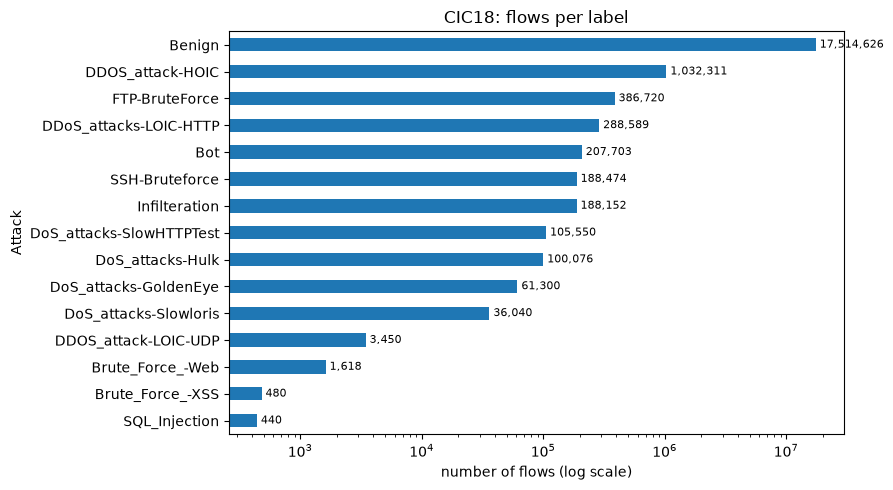

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
distribution["flows"].sort_values().plot.barh(ax=ax)
ax.set_xscale("log")
ax.set_xlabel("number of flows (log scale)")
ax.set_title(f"{SOURCE}: flows per label")
for i, v in enumerate(distribution["flows"].sort_values()):
    ax.text(v, i, f" {v:,}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

### Step 1 — Findings
- **`Label` agrees with `Attack`** on all 20,115,529 rows.
- **11 of the 15 labels are not in the team taxonomy.** The spellings are also inconsistent:
  - `DDOS_attack-` vs `DDoS_attacks-`;
  - `-Bruteforce` vs `-BruteForce`;
  - the typo `Infilteration`;
  - `Brute_Force_-XSS` for an XSS attack.
  A mapping to clean names and families is proposed.
- **Imbalance:** Benign is 87.1% (6.7 benign flows per attack flow).
- **Very small classes:** SQL injection (440), XSS (480), web brute force (1,618) and DDoS LOIC-UDP (3,450).
- **6 of the 9 families are present.** Credential attacks and Web and injection are present here but missing in UNSW. Reconnaissance, Fuzzing, Interception and Data theft are missing.

## Step 2 — Data types and codes *(lab 2.3)*
- Columns that should be numeric but are stored as text
- Timestamps stored as integers
- Codes stored as numbers, and invalid codes
- Proposed solution for each issue

### 2.1 Columns stored as text
Are there text columns that actually contain numbers?

In [14]:
text_cols = df.select_dtypes(exclude="number").columns
for col in text_cols:
    as_number = pd.to_numeric(df[col], errors="coerce")
    print(f"{col:15s} distinct: {df[col].nunique():>9,}   values that are numbers: {as_number.notna().sum():,}")

IPV4_SRC_ADDR   distinct:   181,876   values that are numbers: 0


IPV4_DST_ADDR   distinct:    29,036   values that are numbers: 0


Attack          distinct:        15   values that are numbers: 0


### 2.2 Timestamps stored as integers
`FLOW_START_MILLISECONDS` and `FLOW_END_MILLISECONDS` are milliseconds since 1 January 1970. Converted here only to check that the dates are plausible.

In [15]:
start = pd.to_datetime(df["FLOW_START_MILLISECONDS"], unit="ms")
end = pd.to_datetime(df["FLOW_END_MILLISECONDS"], unit="ms")
print("first flow starts:", start.min())
print("last flow ends:   ", end.max())

first flow starts: 2018-02-14 12:28:07.705000
last flow ends:    2018-03-02 20:06:24.780000


In [16]:
# Flows per capture day
start.dt.date.value_counts().sort_index()

FLOW_START_MILLISECONDS
2018-02-14    2138838
2018-02-15    1665321
2018-02-16    1784129
2018-02-20    1829859
2018-02-21    2712803
2018-02-22    2040128
2018-02-23    1933002
2018-02-27        828
2018-02-28    2032727
2018-03-01    2147533
2018-03-02    1830361
Name: count, dtype: int64

### 2.3 Codes stored as numbers
These columns hold identifiers of a protocol, port, flag or message type. Their numbers have no order or size: an average port or protocol has no meaning.

In [17]:
code_cols = ["L4_SRC_PORT", "L4_DST_PORT", "PROTOCOL", "L7_PROTO",
             "TCP_FLAGS", "CLIENT_TCP_FLAGS", "SERVER_TCP_FLAGS",
             "ICMP_TYPE", "ICMP_IPV4_TYPE", "DNS_QUERY_TYPE", "FTP_COMMAND_RET_CODE"]

pd.DataFrame({
    "dtype": df[code_cols].dtypes.astype(str),
    "distinct values": df[code_cols].nunique(),
    "most common": [df[c].mode()[0] for c in code_cols],
})

,dtype,distinct values,most common
L4_SRC_PORT,int32,65319,3389
L4_DST_PORT,int32,63307,53
PROTOCOL,int32,6,6
L7_PROTO,int32,149,5
TCP_FLAGS,int32,52,0
CLIENT_TCP_FLAGS,int32,50,0
SERVER_TCP_FLAGS,int32,42,0
ICMP_TYPE,int32,282,0
ICMP_IPV4_TYPE,int32,256,0
DNS_QUERY_TYPE,int32,8,0


**TCP flag values above 31.** Besides FIN, SYN, RST, PSH and ACK (1–31), TCP has two congestion flags: ECE = 64 and CWR = 128.

In [18]:
high_flags = df["TCP_FLAGS"] > 31
print(f"flows with ECE/CWR flags: {high_flags.sum():,} ({100 * high_flags.mean():.1f} %)")
(100 * high_flags.groupby(df["Attack"]).mean()).round(1).sort_values(ascending=False).rename("% of class")

flows with ECE/CWR flags: 5,689,311 (28.3 %)


Attack
Bot                         100.0
DDOS_attack-HOIC            100.0
DDoS_attacks-LOIC-HTTP       96.8
Benign                       23.7
SQL_Injection                21.1
Infilteration                11.9
Brute_Force_-Web             11.5
Brute_Force_-XSS              9.0
DDOS_attack-LOIC-UDP          0.0
DoS_attacks-GoldenEye         0.0
DoS_attacks-Hulk              0.0
DoS_attacks-Slowloris         0.0
DoS_attacks-SlowHTTPTest      0.0
FTP-BruteForce                0.0
SSH-Bruteforce                0.0
Name: % of class, dtype: float64

**Protocol numbers present**

In [19]:
protocols = pd.crosstab(df["PROTOCOL"], df["Label"]).rename(columns={0: "benign", 1: "attack"})
protocols["name"] = protocols.index.map({1: "ICMP", 2: "IGMP", 6: "TCP", 17: "UDP", 47: "GRE", 58: "ICMPv6"})
protocols

Label,benign,attack,name
PROTOCOL,,,
1,29960,124,ICMP
2,18464,48,IGMP
6,9856529,2489167,TCP
17,7590915,111564,UDP
47,13,0,GRE
58,18745,0,ICMPv6


### 2.4 `L7_PROTO` stored as a float
A value like `7.37` is two codes in one: the outer protocol (7 = HTTP) and the application inside it (37 = BitTorrent).

In [20]:
has_decimals = df["L7_PROTO"] % 1 != 0
print(f"flows with a decimal L7_PROTO: {has_decimals.sum():,} ({100 * has_decimals.mean():.2f} %)")
df.loc[has_decimals, "L7_PROTO"].value_counts()

flows with a decimal L7_PROTO: 0 (0.00 %)


Series([], Name: count, dtype: int64)

### 2.5 Invalid codes
Codes that do not exist in the official lists:
- **Protocol numbers:** IANA has assigned 0–147; 148–252 are unassigned, 253–254 are for experiments and 255 is reserved.
- **Port 0:** reserved and never used by real TCP/UDP traffic. Other protocols have no ports, so 0 is normal there.
- **DNS query types:** only the types assigned by IANA are valid.
- **ICMP types:** only the types assigned by IANA are valid. Checked on ICMP flows only.

In [21]:
unassigned_proto = df["PROTOCOL"] > 147
print(f"flows with an unassigned protocol number: {unassigned_proto.sum():,}")
print(f"distinct unassigned protocol numbers:     {df.loc[unassigned_proto, 'PROTOCOL'].nunique()}")
df.loc[unassigned_proto, "Attack"].value_counts()

flows with an unassigned protocol number: 0
distinct unassigned protocol numbers:     0


Series([], Name: count, dtype: int64)

In [22]:
tcp_udp = df["PROTOCOL"].isin([6, 17])
port0 = tcp_udp & ((df["L4_SRC_PORT"] == 0) | (df["L4_DST_PORT"] == 0))
print(f"TCP/UDP flows using port 0: {port0.sum():,}")
df.loc[port0, "Attack"].value_counts()

TCP/UDP flows using port 0: 18


Attack
Benign    18
Name: count, dtype: int64

In [23]:
# IANA DNS record types: 1-260 are the standard range, 32768-32769 are DNSSEC-related
dns = df["DNS_QUERY_TYPE"]
invalid_dns = (dns != 0) & ~(dns.between(1, 260) | dns.isin([32768, 32769]))
print(f"flows with an invalid DNS query type: {invalid_dns.sum()}")
df.loc[invalid_dns, ["L4_DST_PORT", "DNS_QUERY_TYPE", "Attack"]]

flows with an invalid DNS query type: 0


,L4_DST_PORT,DNS_QUERY_TYPE,Attack


In [24]:
# IANA ICMP types still in use
valid_icmp = [0, 3, 4, 5, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 30, 40, 41, 42, 43]
icmp = df["PROTOCOL"] == 1
invalid_icmp = icmp & ~df["ICMP_IPV4_TYPE"].isin(valid_icmp)
print(f"ICMP flows: {icmp.sum()}, with an invalid ICMP type: {invalid_icmp.sum()}")
df.loc[invalid_icmp, ["ICMP_TYPE", "ICMP_IPV4_TYPE", "Attack"]].value_counts()

ICMP flows: 30084, with an invalid ICMP type: 0


Series([], Name: count, dtype: int64)

### Step 2 — Findings
- **No numbers hidden in text.** There are 181,876 source and 29,036 destination IP addresses (UNSW: 40).
- **Timestamps** cover 11 capture days, 14 Feb – 2 Mar 2018 (27 Feb has only 828 flows).
- **11 code columns are stored as numbers,** as in UNSW.
- **`L7_PROTO` has no sub-codes** (no decimals).
- **Only 6 protocol numbers occur;** 58 is ICMPv6.
- **TCP flags go up to 223.** 28% of the flows carry the congestion flags ECE/CWR: 100% of Bot and DDoS HOIC, 97% of DDoS LOIC-HTTP, 24% of Benign, which never appear in UNSW (maximum 31). These are valid flags.
- **Invalid codes:** only 18 Benign TCP/UDP flows on port 0. There are no unassigned protocols and no invalid DNS or ICMP types.

## Step 3 — Missing values *(lab 2.2)*
- Real missing values (NaN), count and percentage
- Infinite values and their cause
- Disguised missing values (0 = not applicable)
- Visualisation of the missing values
- Strategy for each type of missing value

### 3.1 Real missing values (NaN)

In [25]:
nan_count = df.isna().sum()
pd.DataFrame({"missing": nan_count, "percent": (100 * nan_count / len(df)).round(3)})[nan_count > 0]

,missing,percent


### 3.2 Infinite values

In [26]:
float_cols = df.select_dtypes("float").columns
print("float columns:", list(float_cols) or "none (integer columns cannot hold inf or NaN)")
inf_count = np.isinf(df[float_cols]).sum() if len(float_cols) else pd.Series(dtype=int)
pd.DataFrame({"infinite": inf_count, "percent": (100 * inf_count / len(df)).round(3)})[inf_count > 0]

float columns: none (integer columns cannot hold inf or NaN)


,infinite,percent


### 3.3 Where do the NaN and inf come from?
The two `..._SECOND_BYTES` columns are a division by the flow duration, so a duration of 0 is the first suspect.
We also check which byte column each one is actually computed from.

In [27]:
zero_duration = df["FLOW_DURATION_MILLISECONDS"] == 0
s2d, d2s = df["SRC_TO_DST_SECOND_BYTES"], df["DST_TO_SRC_SECOND_BYTES"]

print(f"flows with duration 0: {zero_duration.sum():,}")
pd.DataFrame({
    "duration = 0": [s2d[zero_duration].isna().sum(), np.isinf(s2d[zero_duration]).sum(), np.isinf(d2s[zero_duration]).sum()],
    "duration > 0": [s2d[~zero_duration].isna().sum(), np.isinf(s2d[~zero_duration]).sum(), np.isinf(d2s[~zero_duration]).sum()],
}, index=["SRC_TO_DST_SECOND_BYTES NaN", "SRC_TO_DST_SECOND_BYTES inf", "DST_TO_SRC_SECOND_BYTES inf"])

flows with duration 0: 0


,duration = 0,duration > 0
SRC_TO_DST_SECOND_BYTES NaN,0,0
SRC_TO_DST_SECOND_BYTES inf,0,0
DST_TO_SRC_SECOND_BYTES inf,0,0


In [28]:
# Which formula reproduces each column? (share of flows with duration > 0 that match)
ok = ~zero_duration
duration_ms = df.loc[ok, "FLOW_DURATION_MILLISECONDS"]
formulas = pd.DataFrame({
    col: {
        "IN_BYTES / duration (ms)": np.isclose(df.loc[ok, col], df.loc[ok, "IN_BYTES"] / duration_ms, rtol=1e-3).mean(),
        "OUT_BYTES / duration (ms)": np.isclose(df.loc[ok, col], df.loc[ok, "OUT_BYTES"] / duration_ms, rtol=1e-3).mean(),
        "IN_BYTES / duration (s)": np.isclose(df.loc[ok, col], df.loc[ok, "IN_BYTES"] / (duration_ms / 1000), rtol=1e-3).mean(),
    }
    for col in ["SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES"]
})
(100 * formulas).round(2)

,SRC_TO_DST_SECOND_BYTES,DST_TO_SRC_SECOND_BYTES
IN_BYTES / duration (ms),0.14,10.09
OUT_BYTES / duration (ms),20.92,9.28
IN_BYTES / duration (s),0.00,0.00


In [29]:
# The values are integers here: test the formulas with the decimals cut off (floor)
pd.DataFrame({
    col: {
        "floor(IN_BYTES / duration ms)": (np.floor(df["IN_BYTES"] / df["FLOW_DURATION_MILLISECONDS"]) == df[col]).mean(),
        "floor(OUT_BYTES / duration ms)": (np.floor(df["OUT_BYTES"] / df["FLOW_DURATION_MILLISECONDS"]) == df[col]).mean(),
        "share of zeros": (df[col] == 0).mean(),
    }
    for col in ["SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES"]
}).mul(100).round(1)

,SRC_TO_DST_SECOND_BYTES,DST_TO_SRC_SECOND_BYTES
floor(IN_BYTES / duration ms),35.2,70.6
floor(OUT_BYTES / duration ms),78.7,42.7
share of zeros,55.2,65.2


In [30]:
# NaN rows: what do they have in common?
if s2d.isna().any():
    display(df.loc[s2d.isna(), ["IN_PKTS", "OUT_PKTS", "OUT_BYTES", "FLOW_DURATION_MILLISECONDS"]].describe().loc[["min", "max"]])
else:
    print("no NaN to describe")

no NaN to describe


### 3.4 Is the missingness linked to the attack class?

In [31]:
missing_by_class = pd.DataFrame({
    "flows": df["Attack"].value_counts(),
    "NaN or inf (%)": (100 * (s2d.isna() | np.isinf(s2d) | np.isinf(d2s)).groupby(df["Attack"]).mean()).round(2),
}).sort_values("NaN or inf (%)", ascending=False)
missing_by_class

,flows,NaN or inf (%)
Attack,,
Benign,17514626,0.0
Bot,207703,0.0
Brute_Force_-Web,1618,0.0
Brute_Force_-XSS,480,0.0
DDOS_attack-HOIC,1032311,0.0
DDOS_attack-LOIC-UDP,3450,0.0
DDoS_attacks-LOIC-HTTP,288589,0.0
DoS_attacks-GoldenEye,61300,0.0
DoS_attacks-Hulk,100076,0.0


### 3.5 Visualisation

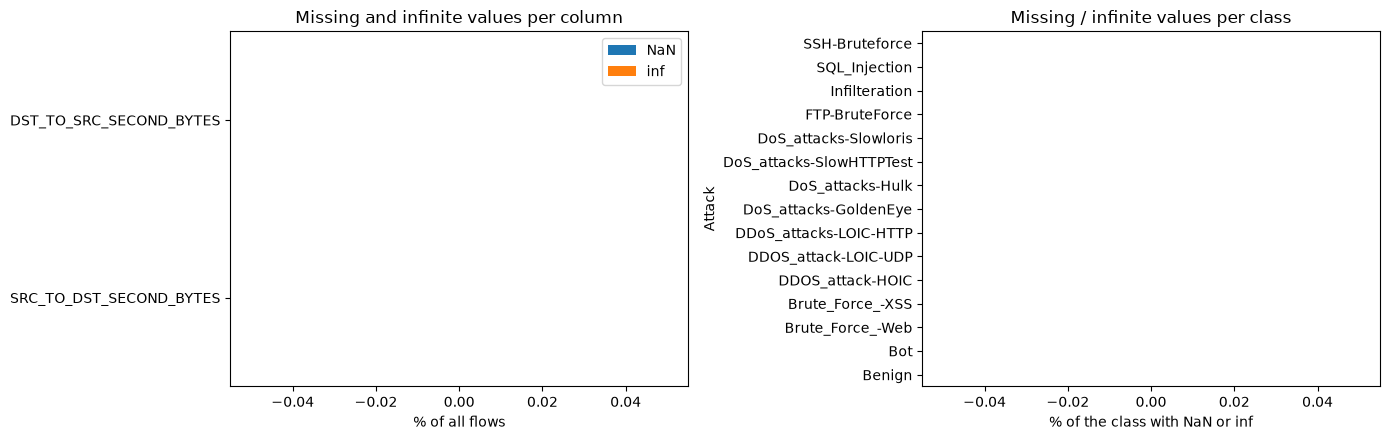

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

pd.DataFrame({
    "NaN": 100 * df[["SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES"]].isna().mean(),
    "inf": 100 * np.isinf(df[["SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES"]]).mean(),
}).plot.barh(stacked=True, ax=axes[0])
axes[0].set_xlabel("% of all flows")
axes[0].set_title("Missing and infinite values per column")

missing_by_class["NaN or inf (%)"].sort_values().plot.barh(ax=axes[1], color="indianred")
axes[1].set_xlabel("% of the class with NaN or inf")
axes[1].set_title("Missing / infinite values per class")
plt.tight_layout()
plt.show()

### 3.6 Disguised missing values
A value of 0 can mean "does not apply" (no DNS query in a web flow) or "not recorded". Each protocol-specific
field should only be filled for its own protocol.

In [33]:
is_dns = (df["L4_DST_PORT"] == 53) | (df["L4_SRC_PORT"] == 53) | (df["L7_PROTO"].astype(int) == 5)
is_ftp = (df["L4_DST_PORT"] == 21) | (df["L4_SRC_PORT"] == 21) | (df["L7_PROTO"].astype(int) == 1)
is_icmp = df["PROTOCOL"] == 1
is_tcp = df["PROTOCOL"] == 6

pd.DataFrame([
    ["DNS_QUERY_TYPE", "DNS flows", is_dns.sum(), (is_dns & (df["DNS_QUERY_TYPE"] == 0)).sum(), (~is_dns & (df["DNS_QUERY_TYPE"] != 0)).sum()],
    ["DNS_TTL_ANSWER", "DNS flows", is_dns.sum(), (is_dns & (df["DNS_TTL_ANSWER"] == 0)).sum(), (~is_dns & (df["DNS_TTL_ANSWER"] != 0)).sum()],
    ["FTP_COMMAND_RET_CODE", "FTP flows", is_ftp.sum(), (is_ftp & (df["FTP_COMMAND_RET_CODE"] == 0)).sum(), (~is_ftp & (df["FTP_COMMAND_RET_CODE"] != 0)).sum()],
    ["ICMP_TYPE", "ICMP flows", is_icmp.sum(), (is_icmp & (df["ICMP_TYPE"] == 0)).sum(), (~is_icmp & (df["ICMP_TYPE"] != 0)).sum()],
    ["ICMP_IPV4_TYPE", "ICMP flows", is_icmp.sum(), (is_icmp & (df["ICMP_IPV4_TYPE"] == 0)).sum(), (~is_icmp & (df["ICMP_IPV4_TYPE"] != 0)).sum()],
    ["TCP_FLAGS", "TCP flows", is_tcp.sum(), (is_tcp & (df["TCP_FLAGS"] == 0)).sum(), (~is_tcp & (df["TCP_FLAGS"] != 0)).sum()],
    ["TCP_WIN_MAX_IN", "TCP flows", is_tcp.sum(), (is_tcp & (df["TCP_WIN_MAX_IN"] == 0)).sum(), (~is_tcp & (df["TCP_WIN_MAX_IN"] != 0)).sum()],
], columns=["column", "applies to", "flows it applies to", "0 where it applies", "filled where it does NOT apply"])

,column,applies to,flows it applies to,0 where it applies,filled where it does NOT apply
0,DNS_QUERY_TYPE,DNS flows,7324830,673,102553
1,DNS_TTL_ANSWER,DNS flows,7324830,53464,0
2,FTP_COMMAND_RET_CODE,FTP flows,495170,495170,0
3,ICMP_TYPE,ICMP flows,30084,50,1557675
4,ICMP_IPV4_TYPE,ICMP flows,30084,51,1557675
5,TCP_FLAGS,TCP flows,12345696,231,0
6,TCP_WIN_MAX_IN,TCP flows,12345696,751664,0


In [34]:
# Which protocol carries the ICMP values that should not be there?
df.loc[~is_icmp & (df["ICMP_TYPE"] != 0), "PROTOCOL"].value_counts()

PROTOCOL
6     1538930
58      18745
Name: count, dtype: int64

**DNS fields outside DNS.** Port 5355 is LLMNR (Link-Local Multicast Name Resolution, nDPI code 154), the
Windows name lookup that uses the DNS message format. A query type there is therefore legitimate.

In [35]:
outside_dns = ~is_dns & (df["DNS_QUERY_TYPE"] != 0)
print(f"flows with a DNS query type outside DNS: {outside_dns.sum():,}")
print("destination ports:", dict(df.loc[outside_dns, "L4_DST_PORT"].value_counts().head(3)))
print("L7_PROTO:         ", dict(df.loc[outside_dns, "L7_PROTO"].value_counts().head(3)))

flows with a DNS query type outside DNS: 102,553
destination ports: {5355: np.int64(102553)}
L7_PROTO:          {154: np.int64(102549), 30: np.int64(4)}


**ICMP fields on protocol 58.** Protocol 58 is ICMPv6, so ICMP types are legitimate there.

In [36]:
df.loc[df["PROTOCOL"] == 58, "ICMP_IPV4_TYPE"].value_counts().rename("ICMPv6 type (143 = MLDv2 report, 135 = neighbour solicitation)")

ICMP_IPV4_TYPE
143    18743
135        2
Name: ICMPv6 type (143 = MLDv2 report, 135 = neighbour solicitation), dtype: int64

In [37]:
# TTL = 0: a packet with TTL 0 is discarded by the network, so 0 means "not recorded"
ttl0 = df["MIN_TTL"] == 0
print(f"flows with MIN_TTL = 0: {ttl0.sum():,}   with MAX_TTL = 0: {(df['MAX_TTL'] == 0).sum():,}")
print("by protocol:", dict(df.loc[ttl0, "PROTOCOL"].value_counts().head(3)))
print("by class:   ", dict(df.loc[ttl0, "Attack"].value_counts()))

flows with MIN_TTL = 0: 7,938,061   with MAX_TTL = 0: 7,938,061
by protocol: {17: np.int64(5824419), 6: np.int64(2103818), 1: np.int64(9800)}


by class:    {'Benign': np.int64(7284294), 'FTP-BruteForce': np.int64(386720), 'Infilteration': np.int64(123928), 'DoS_attacks-SlowHTTPTest': np.int64(105550), 'DoS_attacks-Slowloris': np.int64(20988), 'DDoS_attacks-LOIC-HTTP': np.int64(8325), 'DoS_attacks-GoldenEye': np.int64(7580), 'Brute_Force_-Web': np.int64(566), 'SSH-Bruteforce': np.int64(60), 'Brute_Force_-XSS': np.int64(41), 'DoS_attacks-Hulk': np.int64(9)}


In [38]:
# Share of each class with TTL = 0
(100 * ttl0.groupby(df["Attack"]).mean()).round(1).sort_values(ascending=False).rename("% with TTL = 0")

Attack
DoS_attacks-SlowHTTPTest    100.0
FTP-BruteForce              100.0
Infilteration                65.9
DoS_attacks-Slowloris        58.2
Benign                       41.6
Brute_Force_-Web             35.0
DoS_attacks-GoldenEye        12.4
Brute_Force_-XSS              8.5
DDoS_attacks-LOIC-HTTP        2.9
Bot                           0.0
DDOS_attack-HOIC              0.0
DDOS_attack-LOIC-UDP          0.0
DoS_attacks-Hulk              0.0
SQL_Injection                 0.0
SSH-Bruteforce                0.0
Name: % with TTL = 0, dtype: float64

### Step 3 — Findings
- **No NaN and no infinite values:** every flow lasts at least 1 ms.
- **The two `..._SECOND_BYTES` columns are integers that only partly follow a formula:**
  - `floor(OUT_BYTES ÷ duration ms)` reproduces `SRC_TO_DST_SECOND_BYTES` for 79% of the flows, so the direction is swapped, as in UNSW;
  - 55–65% of the values are 0.
- **ICMP fields are filled for 1,538,930 TCP flows,** where they have no meaning (as in UNSW). On protocol 58 (ICMPv6, 18,745 flows) they are legitimate.
- **DNS fields on 102,553 non-DNS flows** are LLMNR (port 5355), which uses the DNS format, so they are legitimate.
- **`FTP_COMMAND_RET_CODE` is 0 for every flow,** including 495,170 FTP flows: no FTP server reply was ever captured.
- **TTL = 0 ("not recorded") for 7,938,061 flows (39.5%).** This covers 100% of FTP-BruteForce and SlowHTTPTest, 66% of Infiltration and 42% of Benign.

## Step 4 — Logical consistency and impossible values *(lab 2.5)*
- Negative values, invalid ports, end before start
- Relations between columns (min ≤ max, retransmitted ≤ total, ...)
- Protocol-specific fields on the wrong protocol
- Implausible values

### 4.1 Shared team rules (`validate` from `src/config.py`)

In [39]:
shared = validate(df)
print("total violations:", shared["violations"].sum())
shared[shared["violations"] > 0] if shared["violations"].sum() else shared.head(3)

total violations: 0


,check,violations
0,negative values in IN_BYTES,0
1,negative values in IN_PKTS,0
2,negative values in OUT_BYTES,0


### 4.2 Extra rules between columns

In [40]:
size_bins = df[[c for c in df.columns if c.startswith("NUM_PKTS_")]].sum(axis=1)
rules = {
    "end time - start time differs from duration by more than 1 ms":
        ((df["FLOW_END_MILLISECONDS"] - df["FLOW_START_MILLISECONDS"]) - df["FLOW_DURATION_MILLISECONDS"]).abs() > 1,
    "DURATION_IN or DURATION_OUT longer than the flow":
        (df["DURATION_IN"] > df["FLOW_DURATION_MILLISECONDS"]) | (df["DURATION_OUT"] > df["FLOW_DURATION_MILLISECONDS"]),
    "SHORTEST_FLOW_PKT > LONGEST_FLOW_PKT": df["SHORTEST_FLOW_PKT"] > df["LONGEST_FLOW_PKT"],
    "MIN_TTL > MAX_TTL": df["MIN_TTL"] > df["MAX_TTL"],
    "MIN_IP_PKT_LEN = 0 (packet with no size)": df["MIN_IP_PKT_LEN"] == 0,
    "MIN_IP_PKT_LEN differs from SHORTEST_FLOW_PKT": df["MIN_IP_PKT_LEN"] != df["SHORTEST_FLOW_PKT"],
    "MAX_IP_PKT_LEN differs from LONGEST_FLOW_PKT": df["MAX_IP_PKT_LEN"] != df["LONGEST_FLOW_PKT"],
    "packet longer than 1514 bytes (Ethernet limit)": df["LONGEST_FLOW_PKT"] > 1514,
    "retransmitted bytes/packets > total": (df["RETRANSMITTED_IN_BYTES"] > df["IN_BYTES"]) | (df["RETRANSMITTED_OUT_BYTES"] > df["OUT_BYTES"])
        | (df["RETRANSMITTED_IN_PKTS"] > df["IN_PKTS"]) | (df["RETRANSMITTED_OUT_PKTS"] > df["OUT_PKTS"]),
    "IN_BYTES below 20 bytes per packet (smallest IP header)": df["IN_BYTES"] < 20 * df["IN_PKTS"],
    "size-bin counts differ from IN_PKTS + OUT_PKTS": size_bins != df["IN_PKTS"] + df["OUT_PKTS"],
    "inter-arrival MIN > MAX or AVG > MAX": (df["SRC_TO_DST_IAT_MIN"] > df["SRC_TO_DST_IAT_MAX"]) | (df["SRC_TO_DST_IAT_AVG"] > df["SRC_TO_DST_IAT_MAX"])
        | (df["DST_TO_SRC_IAT_MIN"] > df["DST_TO_SRC_IAT_MAX"]) | (df["DST_TO_SRC_IAT_AVG"] > df["DST_TO_SRC_IAT_MAX"]),
    "largest inter-arrival gap longer than the flow": df["SRC_TO_DST_IAT_MAX"] > df["FLOW_DURATION_MILLISECONDS"] + 1,
    "DNS_TTL_ANSWER above 2^31-1 (invalid, RFC 2181)": df["DNS_TTL_ANSWER"] > 2**31 - 1,
    "DNS_TTL_ANSWER above 7 days (allowed but implausible)": df["DNS_TTL_ANSWER"] > 7 * 24 * 3600,
    "TCP flow without any TCP flag": is_tcp & (df["TCP_FLAGS"] == 0),
}
rule_table = pd.DataFrame({
    "violations": {name: int(mask.sum()) for name, mask in rules.items()},
    "percent": {name: round(100 * mask.mean(), 3) for name, mask in rules.items()},
    "main classes": {name: dict(df.loc[mask, "Attack"].value_counts().head(3)) if mask.any() else "" for name, mask in rules.items()},
})
rule_table

,violations,percent,main classes
end time - start time differs from duration by more than 1 ms,0,0.000,
DURATION_IN or DURATION_OUT longer than the flow,4106,0.020,"{'Benign': 3873, 'DDoS_attacks-LOIC-HTTP': 105..."
SHORTEST_FLOW_PKT > LONGEST_FLOW_PKT,0,0.000,
MIN_TTL > MAX_TTL,0,0.000,
MIN_IP_PKT_LEN = 0 (packet with no size),1975355,9.820,"{'Benign': 1948639, 'DDoS_attacks-LOIC-HTTP': ..."
MIN_IP_PKT_LEN differs from SHORTEST_FLOW_PKT,1975355,9.820,"{'Benign': 1948639, 'DDoS_attacks-LOIC-HTTP': ..."
MAX_IP_PKT_LEN differs from LONGEST_FLOW_PKT,0,0.000,
packet longer than 1514 bytes (Ethernet limit),1002,0.005,"{'Infilteration': 712, 'Benign': 193, 'SQL_Inj..."
retransmitted bytes/packets > total,0,0.000,
IN_BYTES below 20 bytes per packet (smallest IP header),0,0.000,


### 4.3 A closer look at the violations

In [41]:
# MIN_IP_PKT_LEN = 0 happens exactly on the one-way flows (no reply packets)
zero_len = df["MIN_IP_PKT_LEN"] == 0
print(f"MIN_IP_PKT_LEN = 0: {zero_len.sum():,}   OUT_PKTS = 0: {(df['OUT_PKTS'] == 0).sum():,}   both: {(zero_len & (df['OUT_PKTS'] == 0)).sum():,}")

MIN_IP_PKT_LEN = 0: 1,975,355   OUT_PKTS = 0: 1,975,367   both: 1,975,355


In [42]:
# Flows whose recorded bytes are too small for the number of packets
too_small = rules["IN_BYTES below 20 bytes per packet (smallest IP header)"]
print("protocols:", dict(df.loc[too_small, "PROTOCOL"].value_counts()))
df.loc[too_small, ["PROTOCOL", "IN_PKTS", "IN_BYTES", "SHORTEST_FLOW_PKT", "Attack"]].head()

protocols: {}


,PROTOCOL,IN_PKTS,IN_BYTES,SHORTEST_FLOW_PKT,Attack


In [43]:
# How far do the size-bin counts differ from the packet counts?
(size_bins - df["IN_PKTS"] - df["OUT_PKTS"]).value_counts().sort_index()

-384           1
-320           1
-126           1
-123           1
-101          68
-100           2
-98            2
-97            4
-79            1
-78            1
-43            1
-40            1
-38            1
-37            2
-36            1
-35            2
-28            1
-13            1
-12            1
-9             1
-7             1
-6             2
-5             2
-3             5
-2           179
-1           719
 0      19015341
 1        546097
 2        542556
 3          4635
 4          3904
 5           983
 6           940
 7            35
 8            36
Name: count, dtype: int64

In [44]:
# Packets above 1514 bytes and the negative differences above
oversized = df["LONGEST_FLOW_PKT"] > 1514
negative = (size_bins - df["IN_PKTS"] - df["OUT_PKTS"]) < 0
print(f"flows with a packet above 1514 bytes: {oversized.sum():,}  protocols: {dict(df.loc[oversized, 'PROTOCOL'].value_counts())}")
print("their largest packet:", df.loc[oversized, "LONGEST_FLOW_PKT"].describe()[["min", "50%", "max"]].to_dict())
print(f"flows whose size bins count FEWER packets than IN_PKTS + OUT_PKTS: {negative.sum():,}, all of them with an oversized packet: {(negative & oversized).sum() == negative.sum()}")
excess = np.maximum(df["DURATION_IN"], df["DURATION_OUT"]) - df["FLOW_DURATION_MILLISECONDS"]
print("DURATION_IN/OUT longer than the flow, by (ms):", dict(excess[excess > 0].value_counts()))

flows with a packet above 1514 bytes: 1,002  protocols: {6: np.int64(1002)}
their largest packet: {'min': 1515.0, '50%': 1918.0, 'max': 65212.0}
flows whose size bins count FEWER packets than IN_PKTS + OUT_PKTS: 1,002, all of them with an oversized packet: True
DURATION_IN/OUT longer than the flow, by (ms): {1: np.int64(4106)}


### 4.4 Extra rules from the ToN-IoT review
Four rules found by Cyrine Chabbar while checking NF-ToN-IoT-v3, now checked on every NetFlow dataset:
- **IAT average below IAT minimum:** an average gap between packets cannot be smaller than the smallest gap.
- **TCP window 0 although packets were sent in that direction:** possibly "not recorded" disguised as 0, like TTL = 0.
- **`OUT_PKTS` = 0 but `MIN_IP_PKT_LEN` > 0:** exceptions to the one-way-flow pattern of 4.3.
- **One-way single-packet flow whose packet is longer than `IN_BYTES`:** the packet cannot be longer than the whole flow.

In [ ]:
tcp = df["PROTOCOL"] == 6
extra = {
    "IAT average below IAT minimum (either direction)":
        (df["SRC_TO_DST_IAT_AVG"] < df["SRC_TO_DST_IAT_MIN"]) | (df["DST_TO_SRC_IAT_AVG"] < df["DST_TO_SRC_IAT_MIN"]),
    "TCP window 0 although packets were sent in that direction":
        tcp & (((df["IN_PKTS"] > 0) & (df["TCP_WIN_MAX_IN"] == 0)) | ((df["OUT_PKTS"] > 0) & (df["TCP_WIN_MAX_OUT"] == 0))),
    "OUT_PKTS = 0 but MIN_IP_PKT_LEN > 0":
        (df["OUT_PKTS"] == 0) & (df["MIN_IP_PKT_LEN"] > 0),
    "one-way single-packet flow longer than IN_BYTES":
        (df["IN_PKTS"] == 1) & (df["OUT_PKTS"] == 0) & (df["LONGEST_FLOW_PKT"] > df["IN_BYTES"]),
}
pd.DataFrame({
    "violations": {k: int(m.sum()) for k, m in extra.items()},
    "percent": {k: round(100 * m.mean(), 3) for k, m in extra.items()},
    "main classes": {k: dict(df.loc[m, "Attack"].value_counts().head(3)) if m.any() else "" for k, m in extra.items()},
})

,violations,percent,main classes
IAT average below IAT minimum (either direction),862525,4.288,"{'Benign': 426853, 'DDOS_attack-HOIC': 378092,..."
TCP window 0 although packets were sent in that direction,1371482,6.818,"{'Benign': 816664, 'FTP-BruteForce': 386720, '..."
OUT_PKTS = 0 but MIN_IP_PKT_LEN > 0,12,0.000,{'Benign': 12}
one-way single-packet flow longer than IN_BYTES,11,0.000,{'Benign': 11}


In [ ]:
# Details: direction of the IAT and window problems, and example rows
print("IAT avg < min, client->server:", int((df["SRC_TO_DST_IAT_AVG"] < df["SRC_TO_DST_IAT_MIN"]).sum()),
      "| server->client:", int((df["DST_TO_SRC_IAT_AVG"] < df["DST_TO_SRC_IAT_MIN"]).sum()))
print("TCP window 0 with packets, IN direction:", int((tcp & (df["IN_PKTS"] > 0) & (df["TCP_WIN_MAX_IN"] == 0)).sum()),
      "| OUT direction:", int((tcp & (df["OUT_PKTS"] > 0) & (df["TCP_WIN_MAX_OUT"] == 0)).sum()))
cols = {
    "IAT average below IAT minimum (either direction)": ["IN_PKTS", "SRC_TO_DST_IAT_MIN", "SRC_TO_DST_IAT_AVG", "SRC_TO_DST_IAT_MAX", "OUT_PKTS", "DST_TO_SRC_IAT_MIN", "DST_TO_SRC_IAT_AVG", "Attack"],
    "TCP window 0 although packets were sent in that direction": ["IN_PKTS", "OUT_PKTS", "TCP_WIN_MAX_IN", "TCP_WIN_MAX_OUT", "CLIENT_TCP_FLAGS", "SERVER_TCP_FLAGS", "Attack"],
    "OUT_PKTS = 0 but MIN_IP_PKT_LEN > 0": ["PROTOCOL", "IN_PKTS", "OUT_PKTS", "SHORTEST_FLOW_PKT", "MIN_IP_PKT_LEN", "Attack"],
    "one-way single-packet flow longer than IN_BYTES": ["PROTOCOL", "IN_PKTS", "IN_BYTES", "LONGEST_FLOW_PKT", "Attack"],
}
for name, mask in extra.items():
    if mask.any():
        print("\n" + name)
        display(df.loc[mask, cols[name]].head(3))

IAT avg < min, client->server: 832382 | server->client: 215581
TCP window 0 with packets, IN direction: 751664 | OUT direction: 620974

IAT average below IAT minimum (either direction)


,IN_PKTS,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_MAX,OUT_PKTS,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_AVG,Attack
47,5,6,1,6,5,0,2,Benign
77,5,1,0,1,5,0,0,Benign
394,5,3,2,8,5,0,2,Benign



TCP window 0 although packets were sent in that direction


,IN_PKTS,OUT_PKTS,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,Attack
11,1,1,62952,0,24,20,Benign
12,1,1,62948,0,24,20,Benign
13,1,0,0,0,20,0,Benign



OUT_PKTS = 0 but MIN_IP_PKT_LEN > 0


,PROTOCOL,IN_PKTS,OUT_PKTS,SHORTEST_FLOW_PKT,MIN_IP_PKT_LEN,Attack
3906162,17,1,0,73,73,Benign
3920831,17,1,0,77,77,Benign
7283255,17,1,0,59,59,Benign



one-way single-packet flow longer than IN_BYTES


,PROTOCOL,IN_PKTS,IN_BYTES,LONGEST_FLOW_PKT,Attack
3906162,17,1,73,101,Benign
3920831,17,1,77,138,Benign
7283255,17,1,59,210,Benign


### Step 4 — Findings
- **The shared team rules pass:** no negative values, invalid ports, end before start, or packets without bytes.
- **`MIN_IP_PKT_LEN` = 0 on 1,975,355 one-way flows,** the same pattern as UNSW. `MAX_IP_PKT_LEN` again equals `LONGEST_FLOW_PKT`.
- **1,002 TCP flows contain a packet above the Ethernet limit of 1514 bytes** (typically about 1,918, up to 65,212). This is an artefact of the capture: the network card merges segments before the capture tool sees them. These packets fall in no size bin, which explains the flows whose bins count fewer packets than `IN_PKTS + OUT_PKTS`.
- **Size bins count 1–8 more packets** than `IN_PKTS + OUT_PKTS` in about 1.1 million flows (5.5%), as in UNSW.
- **Inter-arrival gap:** in 547,302 flows (2.7%) the largest gap is longer than the flow.
- **Rounding only:** `DURATION_IN`/`DURATION_OUT` exceed the flow duration by exactly 1 ms in 4,106 flows.
- **Small issues:** 231 TCP flows without any flag (216 Infiltration); 1 DNS TTL above 7 days; no invalid TTL.
- **4.4 extra rules (from the ToN-IoT review):** IAT average below minimum on 862,525 flows (the minimum skips gaps that round to 0 ms; the average is correct); TCP window 0 despite packets on 1,371,482 flows (100% of server-side zeros are resets); `OUT_PKTS` = 0 but `MIN_IP_PKT_LEN` > 0 on 12; one-packet flows longer than `IN_BYTES` on 11.

## Step 5 — Duplicates *(lab 2.5)*
- Exact duplicate records, overall and per class
- Uniqueness of the flow identifier
- Same behaviour with different labels

### 5.1 Exact duplicate records

In [45]:
# Rows are compared through a 64-bit hash of all their values: same result as df.duplicated(),
# but without building a 9 GB index (the chance of two different rows sharing a hash is negligible).
row_hash = pd.util.hash_pandas_object(df, index=False)
duplicated = row_hash.duplicated()
print(f"exact duplicate rows: {duplicated.sum():,} ({100 * duplicated.mean():.2f} %)")
pd.DataFrame({
    "flows": df["Attack"].value_counts(),
    "duplicates": df.loc[duplicated, "Attack"].value_counts(),
}).fillna(0).astype(int).assign(percent=lambda t: (100 * t["duplicates"] / t["flows"]).round(2)).sort_values("flows", ascending=False)

exact duplicate rows: 628,474 (3.12 %)


,flows,duplicates,percent
Attack,,,
Benign,17514626,121872,0.70
DDOS_attack-HOIC,1032311,0,0.00
FTP-BruteForce,386720,193360,50.00
DDoS_attacks-LOIC-HTTP,288589,0,0.00
Bot,207703,96243,46.34
SSH-Bruteforce,188474,94237,50.00
Infilteration,188152,72347,38.45
DoS_attacks-SlowHTTPTest,105550,0,0.00
DoS_attacks-Hulk,100076,0,0.00


In [46]:
# How many times does each row appear? (1 = unique, 2 = one copy, ...)
copies = row_hash.map(row_hash.value_counts())
pd.crosstab(df["Attack"], copies)

col_0,1,2,3
Attack,,,
Benign,17270882,243744,0
Bot,15217,192486,0
Brute_Force_-Web,1618,0,0
Brute_Force_-XSS,440,40,0
DDOS_attack-HOIC,1032311,0,0
DDOS_attack-LOIC-UDP,0,3450,0
DDoS_attacks-LOIC-HTTP,288589,0,0
DoS_attacks-GoldenEye,0,61300,0
DoS_attacks-Hulk,100076,0,0


### 5.2 Identical flows with a different label
Same values in every feature column, but a different `Attack`.

In [47]:
feature_cols = [c for c in df.columns if c not in ["Label", "Attack"]]
feature_hash = pd.util.hash_pandas_object(df[feature_cols], index=False)
labels_per_flow = df.groupby(feature_hash)["Attack"].nunique()
print("identical flows carrying different labels:", (labels_per_flow > 1).sum())

identical flows carrying different labels: 440


In [48]:
identical_conflict = feature_hash.isin(labels_per_flow.index[labels_per_flow > 1])
print(f"rows: {identical_conflict.sum():,}", dict(df.loc[identical_conflict, "Attack"].value_counts()))
df.loc[identical_conflict, ["IPV4_SRC_ADDR", "IPV4_DST_ADDR", "L4_DST_PORT", "IN_PKTS", "IN_BYTES", "FLOW_START_MILLISECONDS", "Attack"]].sort_values(["FLOW_START_MILLISECONDS", "Attack"]).head(6)

rows: 880 {'Brute_Force_-XSS': np.int64(440), 'SQL_Injection': np.int64(272), 'Brute_Force_-Web': np.int64(168)}


,IPV4_SRC_ADDR,IPV4_DST_ADDR,L4_DST_PORT,IN_PKTS,IN_BYTES,FLOW_START_MILLISECONDS,Attack
10150628,52.14.77.172,172.31.69.28,500,1,528,1519302310148,Brute_Force_-Web
20115069,52.14.77.172,172.31.69.28,500,1,528,1519302310148,Brute_Force_-XSS
10152458,13.58.42.57,172.31.69.28,500,6,3168,1519302337203,Brute_Force_-Web
20115070,13.58.42.57,172.31.69.28,500,6,3168,1519302337203,Brute_Force_-XSS
10156746,52.14.77.172,172.31.69.28,500,6,3168,1519302385732,Brute_Force_-Web
20115071,52.14.77.172,172.31.69.28,500,6,3168,1519302385732,Brute_Force_-XSS


### 5.3 Is there a unique flow identifier?
NetFlow v3 has no flow ID. The natural key is the 5-tuple (addresses, ports, protocol) plus the start time.

In [49]:
flow_key = ["IPV4_SRC_ADDR", "L4_SRC_PORT", "IPV4_DST_ADDR", "L4_DST_PORT", "PROTOCOL", "FLOW_START_MILLISECONDS"]
shared_key = df.duplicated(subset=flow_key, keep=False)
print(f"rows sharing their key with another row: {shared_key.sum():,}")
print(f"... of which are not exact duplicates:   {(shared_key & ~row_hash.duplicated(keep=False)).sum():,}")

rows sharing their key with another row: 1,258,018


... of which are not exact duplicates:   1,344


### 5.4 Same behaviour, different label
Identifiers that do not describe behaviour (IP addresses, source port, timestamps, DNS query ID) are left out.
If the remaining behaviour is identical but the labels differ, no model can tell these flows apart.

In [50]:
behaviour_cols = [c for c in df.columns if c not in
                  ["IPV4_SRC_ADDR", "IPV4_DST_ADDR", "L4_SRC_PORT", "FLOW_START_MILLISECONDS",
                   "FLOW_END_MILLISECONDS", "DNS_QUERY_ID", "Label", "Attack"]]
behaviour = pd.util.hash_pandas_object(df[behaviour_cols], index=False)
labels_per_behaviour = df.groupby(behaviour)["Attack"].nunique()
conflict = behaviour.isin(labels_per_behaviour.index[labels_per_behaviour > 1])
binary_conflict = df[conflict].groupby(behaviour[conflict])["Label"].nunique().gt(1).sum()

print(f"rows with conflicting labels: {conflict.sum():,} in {behaviour[conflict].nunique():,} behaviour groups")
print(f"groups mixing Benign and attack: {binary_conflict}")
pd.DataFrame({
    "flows": df["Attack"].value_counts(),
    "conflicting": df.loc[conflict, "Attack"].value_counts(),
}).fillna(0).astype(int).assign(percent=lambda t: (100 * t["conflicting"] / t["flows"]).round(2)).sort_values("percent", ascending=False)

rows with conflicting labels: 5,333,994 in 21,465 behaviour groups
groups mixing Benign and attack: 21414


,flows,conflicting,percent
Attack,,,
Brute_Force_-XSS,480,480,100.00
FTP-BruteForce,386720,386720,100.00
DoS_attacks-SlowHTTPTest,105550,105550,100.00
SQL_Injection,440,390,88.64
Infilteration,188152,140829,74.85
Brute_Force_-Web,1618,677,41.84
Benign,17514626,4690962,26.78
DDoS_attacks-LOIC-HTTP,288589,8325,2.88
SSH-Bruteforce,188474,60,0.03


In [51]:
# The three largest groups of identical behaviour with different labels
for group in behaviour[conflict].value_counts().index[:3]:
    rows = df[behaviour == group]
    first = rows.iloc[0]
    print(f"protocol {first['PROTOCOL']}, dst port {first['L4_DST_PORT']}, {first['IN_PKTS']} packets / {first['IN_BYTES']} bytes, "
          f"reply packets {first['OUT_PKTS']} ->", dict(rows["Attack"].value_counts()))

protocol 6, dst port 21, 1 packets / 60 bytes, reply packets 1 -> {'FTP-BruteForce': np.int64(386720), 'DoS_attacks-SlowHTTPTest': np.int64(105550), 'SSH-Bruteforce': np.int64(60)}
protocol 17, dst port 53, 1 packets / 64 bytes, reply packets 1 -> {'Benign': np.int64(80302), 'Infilteration': np.int64(1243)}


protocol 17, dst port 53, 1 packets / 68 bytes, reply packets 1 -> {'Benign': np.int64(57696), 'Infilteration': np.int64(633)}


**Which labels are mixed together?**

In [52]:
conflict_labels = (df.loc[conflict].groupby(behaviour[conflict])["Attack"]
                   .agg(lambda s: " + ".join(sorted(s.unique()))))
group_size = behaviour[conflict].value_counts()
pd.DataFrame({"labels": conflict_labels, "rows": group_size.reindex(conflict_labels.index)}) \
  .groupby("labels")["rows"].agg(groups="count", rows="sum").sort_values("rows", ascending=False).head(12)

,groups,rows
labels,,
Benign + Infilteration,21212,4795155
DoS_attacks-SlowHTTPTest + FTP-BruteForce + SSH-Bruteforce,1,492330
Benign + Brute_Force_-Web,159,30550
Benign + DDoS_attacks-LOIC-HTTP,1,8519
Benign + Brute_Force_-Web + Brute_Force_-XSS + SQL_Injection,14,3774
Benign + Brute_Force_-Web + Infilteration,16,2750
Benign + Brute_Force_-XSS + Infilteration,1,538
Benign + Brute_Force_-Web + Brute_Force_-XSS,3,139
Brute_Force_-XSS + SQL_Injection,42,84


**Attack flows whose behaviour also appears as Benign**

In [53]:
benign_behaviour = set(behaviour[df["Attack"] == "Benign"])
same_as_benign = behaviour.isin(benign_behaviour) & (df["Attack"] != "Benign")
pd.DataFrame({
    "flows": df["Attack"].value_counts(),
    "identical to a Benign flow": df.loc[same_as_benign, "Attack"].value_counts(),
}).fillna(0).astype(int).query("`identical to a Benign flow` > 0") \
  .assign(percent=lambda t: (100 * t["identical to a Benign flow"] / t["flows"]).round(1),
          left_if_removed=lambda t: t["flows"] - t["identical to a Benign flow"])

,flows,identical to a Benign flow,percent,left_if_removed
Attack,,,,
Brute_Force_-Web,1618,668,41.3,950
Brute_Force_-XSS,480,436,90.8,44
DDoS_attacks-LOIC-HTTP,288589,8325,2.9,280264
DoS_attacks-Hulk,100076,1,0.0,100075
Infilteration,188152,140826,74.8,47326
SQL_Injection,440,344,78.2,96


**FTP-BruteForce and DoS SlowHTTPTest: what do their flows look like?**

In [54]:
profile = []
for label in ["FTP-BruteForce", "DoS_attacks-SlowHTTPTest", "SSH-Bruteforce"]:
    rows = df[df["Attack"] == label]
    profile.append({
        "label": label,
        "distinct behaviours": behaviour[df["Attack"] == label].nunique(),
        "destination ports": dict(rows["L4_DST_PORT"].value_counts().head(2)),
        "packets in / out": dict((rows["IN_PKTS"].astype(str) + " / " + rows["OUT_PKTS"].astype(str)).value_counts().head(2)),
        "client flags": dict(rows["CLIENT_TCP_FLAGS"].value_counts().head(2)),
        "server flags": dict(rows["SERVER_TCP_FLAGS"].value_counts().head(2)),
    })
pd.DataFrame(profile).set_index("label")

,distinct behaviours,destination ports,packets in / out,client flags,server flags
label,,,,,
FTP-BruteForce,1,{21: 386720},{'1 / 1': 386720},{2: 386720},{20: 386720}
DoS_attacks-SlowHTTPTest,1,{21: 105550},{'1 / 1': 105550},{2: 105550},{20: 105550}
SSH-Bruteforce,93980,"{22: 188414, 21: 60}","{'23 / 23': 86716, '23 / 21': 28044}","{27: 188414, 2: 60}","{27: 188414, 20: 60}"


### Step 5 — Findings
- **628,474 exact duplicate rows (3.12%).**
  - Every flow of FTP-BruteForce, SSH-Bruteforce, DoS GoldenEye, DoS Slowloris and DDoS LOIC-UDP appears **exactly twice**, as do most Bot and Infiltration flows. Those captures were recorded twice.
- **880 completely identical rows carry two different web-attack labels** (XSS / SQL injection / web brute force). They are the same attacker, server and millisecond.
- **The flow key is almost unique:** only 1,344 non-duplicate rows share their 5-tuple + start time.
- **Same behaviour, different label: 5.3 million rows,** this time **mixing Benign and attacks**:
  - **Infiltration:** 140,826 of 188,152 flows (75%) are identical to Benign flows (e.g. normal DNS lookups). It looks like all traffic of the infected machine was labelled as attack.
  - **Web attacks:** 436 of 480 XSS, 344 of 440 SQL injection and 668 of 1,618 web brute-force flows are identical to Benign web requests.
  - **DDoS LOIC-HTTP:** 8,325 flows (2.9%) are identical to Benign.
  - **FTP-BruteForce:** all 386,720 flows are one single behaviour, a SYN to port 21 answered by RST (connection refused). No password was ever tried.
  - **DoS SlowHTTPTest:** all 105,550 flows are **that same refused FTP connection.** There is no HTTP traffic at all, so the label is wrong.

## Step 6 — Outliers *(lab 2.4)*
- Potential outliers using statistical methods (IQR, z-score)
- Box plots per attack class
- Which outliers are legitimate and which are errors
- How each type of outlier will be handled

### 6.1 Statistical outliers (IQR and z-score)
Only measurement columns. Codes, timestamps and labels are excluded, and inf/NaN are ignored (Step 3).
- **IQR rule:** below Q1 − 1.5·IQR or above Q3 + 1.5·IQR
- **z-score rule:** more than 3 standard deviations from the mean

In [55]:
not_measures = code_cols + ["FLOW_START_MILLISECONDS", "FLOW_END_MILLISECONDS", "DNS_QUERY_ID", "Label"]
measures = [c for c in df.select_dtypes("number").columns if c not in not_measures]
is_attack = df["Label"] == 1

rows = []
for col in measures:
    x = df[col].replace([np.inf, -np.inf], np.nan)
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    iqr_out = (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)
    z_out = (x - x.mean()).abs() > 3 * x.std()
    rows.append({"column": col, "median": x.median(), "max": x.max(),
                 "IQR outliers %": 100 * iqr_out.mean(), "z outliers %": 100 * z_out.mean(),
                 "IQR % in Benign": 100 * iqr_out[~is_attack].mean(), "IQR % in attacks": 100 * iqr_out[is_attack].mean()})
outliers = pd.DataFrame(rows).set_index("column").round(2).sort_values("IQR outliers %", ascending=False)
outliers

,median,max,IQR outliers %,z outliers %,IQR % in Benign,IQR % in attacks
column,,,,,,
DST_TO_SRC_IAT_MIN,0.0,60935,24.69,0.60,26.96,9.39
NUM_PKTS_1024_TO_1514_BYTES,0.0,110111,23.76,0.04,26.08,8.11
SRC_TO_DST_IAT_MIN,0.0,60947,22.03,0.22,22.10,21.51
DST_TO_SRC_SECOND_BYTES,0.0,2015,18.22,2.18,13.72,48.55
SRC_TO_DST_SECOND_BYTES,0.0,46938,17.75,2.44,13.80,44.32
SRC_TO_DST_IAT_MAX,25.0,60970,17.19,5.02,17.34,16.21
SRC_TO_DST_IAT_STDDEV,0.0,30403,16.94,4.53,17.02,16.42
SRC_TO_DST_IAT_AVG,15.0,60947,16.01,1.83,16.15,15.04
DURATION_OUT,0.0,120999,15.85,6.83,17.24,6.43


### 6.2 Box plots per class (log scale)
At most 20,000 flows per class, so every class is visible.

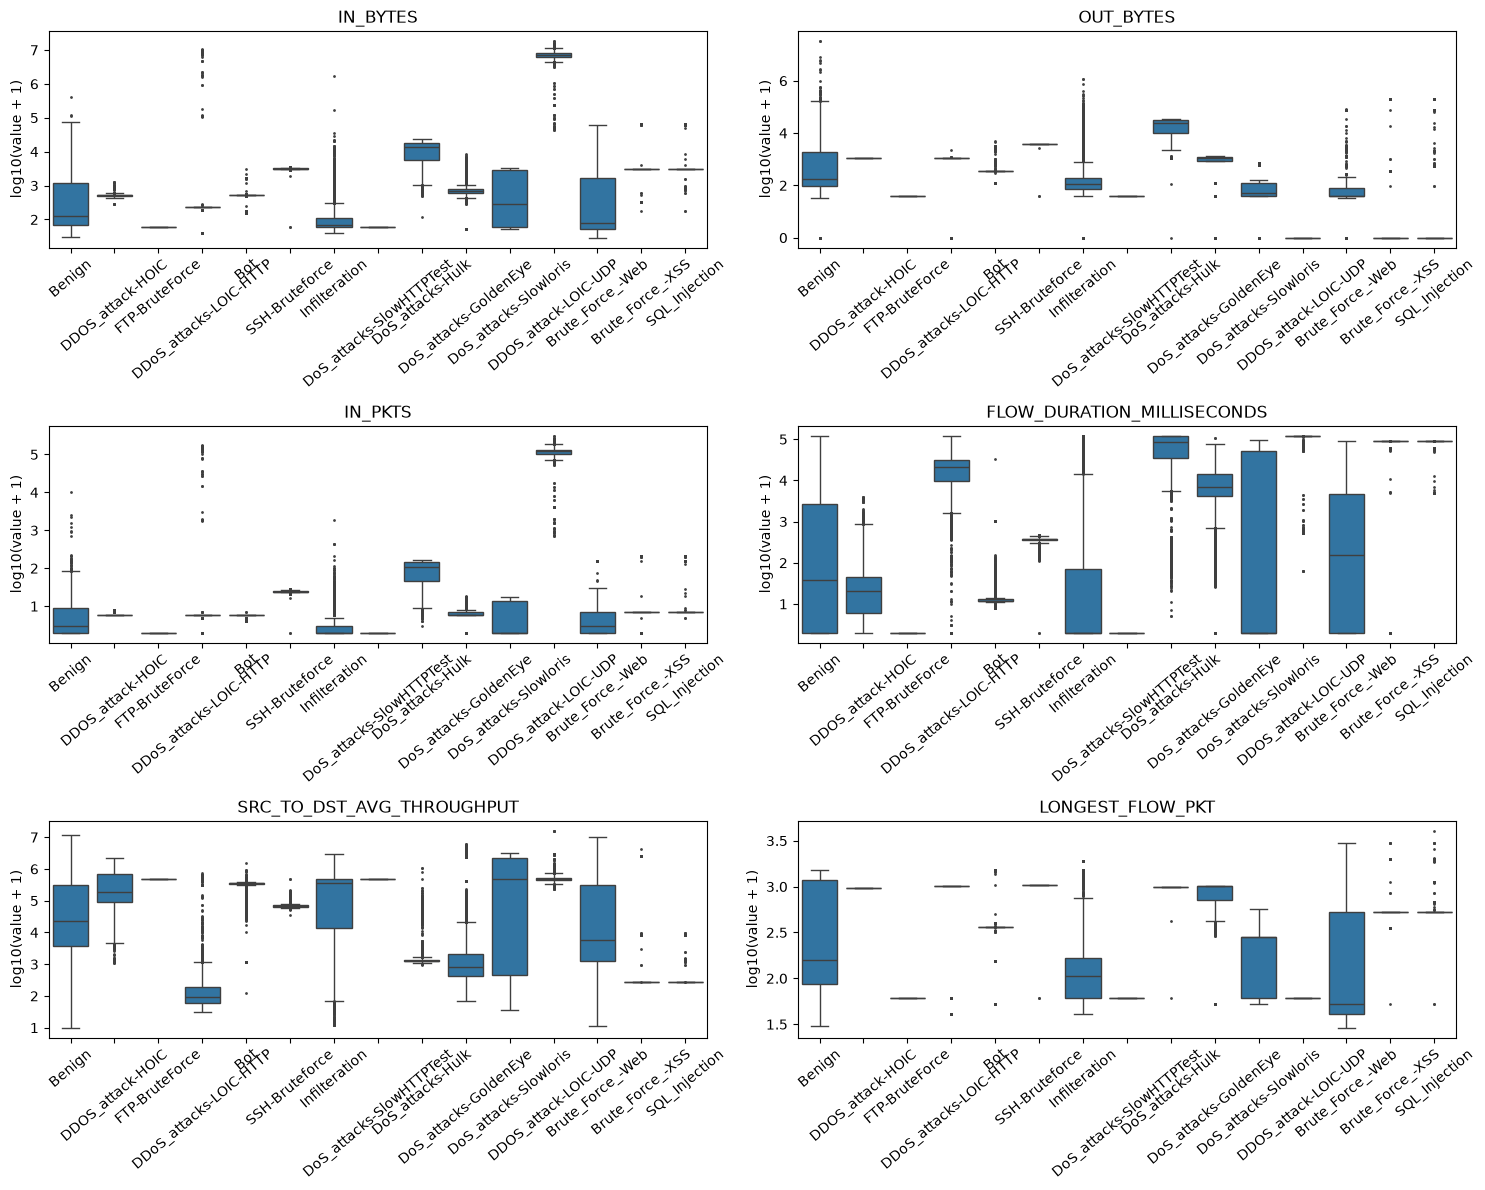

In [56]:
rank = pd.Series(np.random.default_rng(42).random(len(df)), index=df.index).groupby(df["Attack"]).rank()
sample = df[rank <= 20_000]
order = df["Attack"].value_counts().index

key_features = ["IN_BYTES", "OUT_BYTES", "IN_PKTS", "FLOW_DURATION_MILLISECONDS", "SRC_TO_DST_AVG_THROUGHPUT", "LONGEST_FLOW_PKT"]
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
for ax, col in zip(axes.flat, key_features):
    sns.boxplot(x=sample["Attack"], y=np.log10(sample[col] + 1), order=order, ax=ax, fliersize=1)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("log10(value + 1)")
    ax.tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.show()

### 6.3 Physical limits
An extreme value is an error only if it is impossible on a real network.

In [57]:
pd.DataFrame({
    "maximum": [df["LONGEST_FLOW_PKT"].max(), df["FLOW_DURATION_MILLISECONDS"].max() / 1000,
                df["SRC_TO_DST_AVG_THROUGHPUT"].max() / 1e6, df["IN_BYTES"].max() / 1e6, df["DNS_TTL_ANSWER"].max() / (3600 * 24 * 365)],
    "limit": ["1514 bytes (Ethernet frame)", "~120 s (exporter splits longer flows)", "link speed (100 Mbps / 1 Gbps)",
              "none", "2^31-1 s = 68 years (RFC 2181)"],
}, index=["longest packet (bytes)", "longest flow (s)", "highest throughput (Mbps)", "largest flow (MB)", "largest DNS TTL (years)"])

,maximum,limit
longest packet (bytes),65212.000000,1514 bytes (Ethernet frame)
longest flow (s),120.999000,~120 s (exporter splits longer flows)
highest throughput (Mbps),19.576000,link speed (100 Mbps / 1 Gbps)
largest flow (MB),18.597420,none
largest DNS TTL (years),0.114155,2^31-1 s = 68 years (RFC 2181)


### 6.4 Skewness

In [58]:
pd.Series({c: df[c].replace([np.inf, -np.inf], np.nan).skew() for c in measures}).sort_values(ascending=False).head(10).round(1)

DNS_TTL_ANSWER                 4466.8
RETRANSMITTED_OUT_BYTES        1656.0
RETRANSMITTED_OUT_PKTS         1590.5
RETRANSMITTED_IN_BYTES          482.8
OUT_PKTS                        204.3
OUT_BYTES                       187.7
NUM_PKTS_1024_TO_1514_BYTES     184.7
NUM_PKTS_512_TO_1024_BYTES      127.4
IN_PKTS                          75.4
NUM_PKTS_UP_TO_128_BYTES         75.4
dtype: float64

### Step 6 — Findings
- **The IQR rule flags up to 25% of the flows per column.** As in UNSW, the distributions are extremely skewed (skewness up to 4,467).
- **Extremes are long-tail traffic or attack patterns,** not errors.
- **Physical limits are respected,** apart from the 1,002 oversized packets (Step 4):
  - the longest flow is 121 s (the exporter's timeout);
  - the highest throughput is 375 Mbps, below 1 Gbps;
  - the largest DNS TTL is 41 days, which is valid.

## Step 7 — Feature usefulness
- Constant or near-constant columns
- Identifier columns
- Leakage between target columns

### 7.1 Constant or near-constant columns

In [59]:
top_share = df.apply(lambda c: c.value_counts(normalize=True).iloc[0])
(100 * top_share[top_share > 0.99]).round(2).rename("% of flows with the most common value")

FTP_COMMAND_RET_CODE    100.0
Name: % of flows with the most common value, dtype: float64

### 7.2 Identifier columns: do the IP addresses reveal the label?

In [60]:
by_ip = pd.crosstab(df["IPV4_SRC_ADDR"], df["Attack"] != "Benign").rename(columns={False: "benign flows", True: "attack flows"})
print("source IPs with only attacks:", (by_ip["benign flows"] == 0).sum(),
      "| only benign:", (by_ip["attack flows"] == 0).sum(),
      "| both:", ((by_ip["benign flows"] > 0) & (by_ip["attack flows"] > 0)).sum())
by_ip.sort_values("attack flows", ascending=False).head(6)

source IPs with only attacks: 195 | only benign: 180718 | both: 963


Attack,benign flows,attack flows
IPV4_SRC_ADDR,,
18.221.219.4,0,386720
13.58.98.64,0,188474
18.218.229.235,0,133850
18.216.200.189,0,133776
18.219.9.1,0,132968
18.218.55.126,0,132355


### 7.3 Do the timestamps reveal the label?

In [61]:
hour = pd.to_datetime(df["FLOW_START_MILLISECONDS"], unit="ms").dt.floor("h")
per_hour = pd.crosstab(hour, df["Label"]).rename(columns={0: "benign", 1: "attack"})
print(f"hours with traffic: {len(per_hour)}, hours with attacks: {(per_hour['attack'] > 0).sum()}")
print(f"hours in which more than 90% of the flows are attacks: {(per_hour['attack'] / per_hour.sum(axis=1) > 0.9).sum()}")
# Which attack happens on which day
pd.crosstab(hour.dt.date, df["Attack"]).T

hours with traffic: 141, hours with attacks: 53
hours in which more than 90% of the flows are attacks: 0


FLOW_START_MILLISECONDS,2018-02-14,2018-02-15,2018-02-16,2018-02-20,2018-02-21,2018-02-22,2018-02-23,2018-02-27,2018-02-28,2018-03-01,2018-03-02
Attack,,,,,,,,,,,
Benign,1563644,1567981,1578503,1541270,1677042,2037590,1933002,828,1948400,2043708,1622658
Bot,0,0,0,0,0,0,0,0,0,0,207703
Brute_Force_-Web,0,0,0,0,0,1618,0,0,0,0,0
Brute_Force_-XSS,0,0,0,0,0,480,0,0,0,0,0
DDOS_attack-HOIC,0,0,0,0,1032311,0,0,0,0,0,0
DDOS_attack-LOIC-UDP,0,0,0,0,3450,0,0,0,0,0,0
DDoS_attacks-LOIC-HTTP,0,0,0,288589,0,0,0,0,0,0,0
DoS_attacks-GoldenEye,0,61300,0,0,0,0,0,0,0,0,0
DoS_attacks-Hulk,0,0,100076,0,0,0,0,0,0,0,0


### 7.4 Redundant columns
Pairs with an absolute correlation above 0.98, plus columns that can be computed exactly from others.

In [62]:
# Correlation on a random sample of 1 million flows (the full 20M x 40 matrix would need ~6 GB)
corr_sample = df.sample(1_000_000, random_state=42)
corr = corr_sample[measures + ["TCP_FLAGS", "CLIENT_TCP_FLAGS", "SERVER_TCP_FLAGS", "ICMP_TYPE", "ICMP_IPV4_TYPE"]].replace([np.inf, -np.inf], np.nan).corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
print(pairs[pairs > 0.98].sort_values(ascending=False).round(4).to_string())
print()
print("TCP_FLAGS == CLIENT_TCP_FLAGS | SERVER_TCP_FLAGS:", (df["TCP_FLAGS"] == (df["CLIENT_TCP_FLAGS"] | df["SERVER_TCP_FLAGS"])).mean())
print("ICMP_IPV4_TYPE == ICMP_TYPE // 256:             ", (df["ICMP_IPV4_TYPE"] == df["ICMP_TYPE"] // 256).mean())

LONGEST_FLOW_PKT            MAX_IP_PKT_LEN                 1.0000
ICMP_TYPE                   ICMP_IPV4_TYPE                 1.0000
IN_PKTS                     NUM_PKTS_UP_TO_128_BYTES       1.0000
TCP_FLAGS                   CLIENT_TCP_FLAGS               0.9993
FLOW_DURATION_MILLISECONDS  DURATION_IN                    0.9991
MIN_TTL                     MAX_TTL                        0.9981
OUT_BYTES                   OUT_PKTS                       0.9969
                            NUM_PKTS_1024_TO_1514_BYTES    0.9950
OUT_PKTS                    NUM_PKTS_1024_TO_1514_BYTES    0.9937
FLOW_DURATION_MILLISECONDS  DURATION_OUT                   0.9838
DURATION_IN                 DURATION_OUT                   0.9829

TCP_FLAGS == CLIENT_TCP_FLAGS | SERVER_TCP_FLAGS: 1.0
ICMP_IPV4_TYPE == ICMP_TYPE // 256:              1.0


### 7.5 Does the TTL reveal the label?
The TTL depends on the operating system of the sending machine and on its distance in the network. Step 6
showed that every attack flow is a TTL "outlier".

In [63]:
ttl_table = pd.crosstab(df["MAX_TTL"], df["Label"]).rename(columns={0: "benign", 1: "attack"})
print(ttl_table[ttl_table.sum(axis=1) > 500])

attack_only_ttl = ttl_table.index[ttl_table["benign"] == 0]
benign_only_ttl = ttl_table.index[ttl_table["attack"] == 0]
print(f"\nflows with a TTL never seen in benign traffic: {df['MAX_TTL'].isin(attack_only_ttl).sum():,} (all attacks)")
print(f"flows with a TTL never seen in attack traffic: {df['MAX_TTL'].isin(benign_only_ttl).sum():,} (all benign)")

Label     benign  attack
MAX_TTL                 
0        7284294  653767
1         178129      93
4           2096      28
28          1211       2
29           858       2
...          ...     ...
235        20147      30
236         3568      23
237         1009      15
238         1951       0
240          734      18

[71 rows x 2 columns]

flows with a TTL never seen in benign traffic: 1 (all attacks)
flows with a TTL never seen in attack traffic: 8,000 (all benign)


In [64]:
print("most common MAX_TTL values, benign:", dict(df.loc[df["Label"] == 0, "MAX_TTL"].value_counts().head(6)))
print("most common MAX_TTL values, attack:", dict(df.loc[df["Label"] == 1, "MAX_TTL"].value_counts().head(6)))

most common MAX_TTL values, benign: {0: np.int64(7284294), 128: np.int64(5786113), 100: np.int64(570642), 101: np.int64(567835), 102: np.int64(411256), 103: np.int64(406701)}
most common MAX_TTL values, attack: {127: np.int64(1316278), 0: np.int64(653767), 63: np.int64(357296), 128: np.int64(254958), 105: np.int64(6446), 98: np.int64(2528)}


### Step 7 — Findings
- **`FTP_COMMAND_RET_CODE` is constant** (100% zero).
  - Unlike UNSW, `SRC_TO_DST_IAT_MIN` and `DST_TO_SRC_IAT_MIN` are **not** near-constant here.
- **IP addresses leak the label:** 195 source IPs send only attacks (the attacker machines 18.x / 13.x / 52.x). One IP alone sends all 386,720 FTP-BruteForce flows.
- **Time leaks the label:** each attack type happens on one specific day.
- **TTL is a weaker fingerprint than in UNSW:**
  - attacks mostly use 127 and 63, Benign mostly 128 and 100–103;
  - 39.5% of all flows have TTL 0;
  - only 1 flow has a TTL that never appears in Benign traffic.
- **Exact copies,** as in UNSW: `TCP_FLAGS` = client OR server flags, `ICMP_IPV4_TYPE` = `ICMP_TYPE` ÷ 256, `MAX_IP_PKT_LEN` = `LONGEST_FLOW_PKT`.
- **Very high correlations,** partly different from UNSW: `IN_PKTS` / `NUM_PKTS_UP_TO_128_BYTES` (1.00) and `OUT_BYTES` / `OUT_PKTS` (0.997).

## Step 8 — Decisions

Decisions only: **nothing is changed in the data in this notebook.** The last column says whether the same
problem was found in UNSW (`01_unsw.ipynb`, decision numbers in brackets). Decisions that change or remove
columns must be the same for all four NetFlow datasets, so they are agreed with the team first.

| # | Check that found it | Problem | Columns / labels | Size | Decision | Reason | Also in UNSW? |
|---|---|---|---|---|---|---|---|
| 1 | 1.3 taxonomy mapping | 11 of 15 labels missing from the team taxonomy | all labels except Benign, Bot, Infilteration | 11 labels, 2,208,048 flows | Add them to `config.py` with the proposed mapping (table in 1.3), after the team agrees. `Brute_Force_-Web` goes to *Credential attacks* (password guessing on a web login). | `map_labels` stops otherwise; the detailed name (HOIC, Hulk, ...) is kept as `attack_label`. | **No**: all UNSW labels were already in the taxonomy |
| 2 | 1.1 label spellings | Inconsistent label formatting | `DDOS_attack-` / `DDoS_attacks-`, `-Bruteforce` / `-BruteForce`, `Infilteration`, `Brute_Force_-XSS` | 15 labels | Solved by the mapping in #1 (clean names: "DDoS HOIC", "Infiltration", "XSS", ...). The raw `Attack` column is not edited. | One spelling per class. | **No**: UNSW labels were clean |
| 3 | 1.4 class distribution | Class imbalance | `Attack` | Benign 87.1% (6.7 : 1) | Delete nothing now. Sampling (max 200k per label) reduces the large classes later; evaluate with macro-F1 and per-class recall. | Accuracy would be misleading. | **Yes** (#1): stronger in UNSW (94.6%) |
| 4 | 1.4 class distribution | Very small classes | SQL injection, XSS, web brute force, DDoS LOIC-UDP | 440 / 480 / 1,618 / 3,450 flows | Keep all; also report family-level results. See #30 for how much is left after the label-noise removal. | Real attack data, too small to learn reliably at label level. | **Yes** (#2): Worms (158) |
| 5 | 1.3 family totals | 6 of 9 families present | missing: Reconnaissance, Fuzzing and crypto, Interception, Data theft | 4 families | No change; documented. CIC18 adds *Credential attacks* and *Web and injection*, which UNSW lacks. | Together UNSW + CIC18 cover 7 families; the other two come from ToN-IoT / BoT-IoT. | **Yes** (#3): 6 of 9, but different families |
| 6 | 1.2 `Label` vs `Attack` | Two target columns | `Label`, `Attack` | 0 disagreements | Keep both as targets; never use one as a feature for the other. | Leakage. | **Yes** (#4) |
| 7 | 2.2 timestamps | Timestamps stored as integers | `FLOW_START_MILLISECONDS`, `FLOW_END_MILLISECONDS` | 2 columns | Convert to datetime for analysis only; not model features (#35). | Not readable as dates. | **Yes** (#5) |
| 8 | 2.3 code columns | Codes stored as numbers | 11 code columns | 11 columns | Treat as categorical; encoding decided in feature engineering. | Arithmetic on codes has no meaning. | **Yes** (#6) |
| 9 | 0.4 column comparison + 2.4 | `L7_PROTO` type differs between datasets | `L7_PROTO` | integer here, float in UNSW | Same representation as UNSW #7: main protocol + sub-protocol, with sub-protocol = 0 here. | The merged column must have one type and one meaning. | **Partly** (#7): UNSW has sub-codes and lost zeros |
| 10 | 0.4 comparison + 3.3 formula checks | `..._SECOND_BYTES`: integer here, float in UNSW; only partly reproducible; direction swapped | `SRC_TO_DST_SECOND_BYTES`, `DST_TO_SRC_SECOND_BYTES` | 100% of flows; 55–65% zeros | **Drop both columns**, as in UNSW. | Wrong meaning, a different type per dataset, and the `..._AVG_THROUGHPUT` columns carry the information. | **Partly** (#9–11): in UNSW they also had NaN/inf |
| 11 | 2.3 TCP flags above 31 | Congestion flags ECE/CWR present | `TCP_FLAGS`, `CLIENT_TCP_FLAGS`, `SERVER_TCP_FLAGS` | 28% of flows; 100% of Bot and DDoS HOIC, 24% of Benign | Keep; valid TCP flags. Check in the EDA whether they make CIC18 traffic look different from UNSW. | Real protocol behaviour, but a possible difference between networks (SQ2). | **No**: UNSW never exceeds 31 |
| 12 | 2.5 invalid codes | Port 0 in TCP/UDP | `L4_SRC_PORT`, `L4_DST_PORT` | 18 Benign flows | Keep. | Negligible. | **Partly** (#8): 6 attack flows, plus unassigned protocols |
| 13 | 2.3 protocols + 3.6 | ICMPv6 (protocol 58) inside IPv4 flows | `PROTOCOL`, ICMP fields | 18,745 Benign flows | Keep; ICMP fields are valid for protocol 58. | Normal IPv6 neighbour discovery / multicast traffic. | **No** |
| 14 | 3.1–3.2 NaN / inf | No missing or infinite values | all | 0 | No action. | Every flow lasts at least 1 ms. | **No**: UNSW had 63,425 NaN and 181,561 inf |
| 15 | 3.6 disguised missing | ICMP fields filled for TCP flows | `ICMP_TYPE`, `ICMP_IPV4_TYPE` | 1,538,930 flows | Set both to 0 when `PROTOCOL` is not 1 or 58. | Meaningless outside ICMP. | **Yes** (#12): 1,754,341 flows |
| 16 | 3.6 disguised missing | DNS query type on non-DNS flows | `DNS_QUERY_TYPE` | 102,553 flows on port 5355 | Keep. | LLMNR uses the DNS message format, so the value is real. | **No** |
| 17 | 3.6 + 7.1 | FTP return code never filled | `FTP_COMMAND_RET_CODE` | 100% zero, including 495,170 FTP flows | Keep for now; decide in feature selection with all 4 datasets. | Here it is constant (no server ever replied); in UNSW it is informative. A column that is only non-zero in one dataset could reveal the dataset instead of the attack. | **No**: UNSW has 16 real codes |
| 18 | 3.6 + 7.5 | TTL = 0 ("not recorded") | `MIN_TTL`, `MAX_TTL` | 7,938,061 flows (39.5%); 100% of FTP-BruteForce and SlowHTTPTest | Keep 0 as "unknown"; TTL is not used as a model feature (#36). | Too much missing to impute, and TTL is a host fingerprint. | **Yes** (#13): only 27,147 flows (1.1%) |
| 19 | 4.2 rules + 4.3 | `MIN_IP_PKT_LEN` = 0 on one-way flows; both columns copy others | `MIN_IP_PKT_LEN`, `MAX_IP_PKT_LEN` | 1,975,355 flows | **Drop both**, as in UNSW. | Exact copies; the copy contains the error. | **Yes** (#15): 66,121 flows |
| 20 | 4.2 rules + 4.3 | Packets above the Ethernet limit (1514 bytes) | `LONGEST_FLOW_PKT`, `MAX_IP_PKT_LEN` | 1,002 TCP flows (up to 65,212 bytes) | Keep; document as a capture artefact (segment merging by the network card). | Not an error of the traffic, and too few to matter. | **No**: UNSW maximum is 1,508 |
| 21 | 4.2 rules + 4.3 | Size bins do not add up to the packet count | 5 `NUM_PKTS_*` columns | 1,100,188 flows (5.5%) | Keep; document. | Cannot tell which counter is right; the negative cases are the oversized packets of #20. | **Yes** (#17): 20% of flows |
| 22 | 4.2 rules | Largest packet gap longer than the flow | `SRC_TO_DST_IAT_MAX` | 547,302 flows (2.7%) | Keep; document. | Exporter timing inconsistency. | **Yes** (#18): 1.4% |
| 23 | 4.2 rules + 4.3 | `DURATION_IN`/`DURATION_OUT` longer than the flow | `DURATION_IN`, `DURATION_OUT` | 4,106 flows, always by 1 ms | No action. | Rounding. | **No** (0 in UNSW) |
| 24 | 4.2 rules | TCP flow without any flag | `TCP_FLAGS` | 231 flows (216 Infiltration) | Keep. | Negligible. | **Yes** (#21): 7 flows |
| 25 | 4.2 rules + 6.3 | DNS TTL | `DNS_TTL_ANSWER` | 1 flow above 7 days, none invalid | Keep. | Allowed by the standard. | **Partly** (#19): UNSW had 12 invalid values |
| 26 | 5.1 exact duplicates | Exact duplicate rows; several attack captures recorded twice | all | 628,474 rows (3.12%); 50% of FTP, SSH, GoldenEye, Slowloris, LOIC-UDP | **Remove, keeping the first copy** (shared `clean()` rule). | The copies add no information and would land in both train and test. | **Yes** (#22): only 0.63% |
| 27 | 5.2 identical flows | The same flow carries two different labels | XSS, SQL injection, web brute force | 880 rows | **Remove all copies** of these flows. | The correct label cannot be known. | **No** (0 in UNSW) |
| 28 | 5.4 behaviour + FTP/SlowHTTPTest profile | **SlowHTTPTest is mislabelled:** all its flows are refused FTP connections | `DoS_attacks-SlowHTTPTest` (+ 60 port-21 flows labelled SSH-Bruteforce) | 105,550 + 60 flows | **Remove these flows.** | They contain no HTTP traffic and are identical to FTP-BruteForce, so they would teach the model a wrong DoS pattern. | **No** |
| 29 | 5.4 FTP profile | FTP-BruteForce is only refused connections (one single behaviour) | `FTP-BruteForce` | 386,720 flows, 1 distinct behaviour | Keep; document that it shows failed connection attempts, not password guessing. After #26 there are 193,360 identical flows. | It is still attack traffic (a scan of a closed FTP port), but it represents only one pattern. | **No** |
| 30 | 5.4 attack flows identical to Benign | **Attack labels on normal traffic** | Infiltration, XSS, SQL injection, web brute force, DDoS LOIC-HTTP | 140,826 / 436 / 344 / 668 / 8,325 flows | **Remove the attack flows whose behaviour also appears as Benign.** Consequence: Infiltration keeps 47,326 flows, XSS 44, SQL injection 96, web brute force 950 (with #27 as well: no XSS flow and 53 different SQL-injection behaviours remain). | The same behaviour cannot be both normal and an attack; keeping both teaches the model contradictions. | **Partly** (#24): UNSW conflicts were only between attack types, never with Benign |
| 31 | 5.3 flow key | No unique flow identifier | 5-tuple + start time | 1,344 non-duplicate rows share a key | No action. | Exporter detail; negligible here. | **Yes** (#23): 483,517 rows |
| 32 | 6.1 IQR / z-score + 6.2 box plots | IQR flags up to 25% of flows | measurement columns | skewness up to 4,467 | Keep all; log transform in feature engineering. | Long-tail traffic and attack patterns, not errors. | **Yes** (#25) |
| 33 | 6.3 physical limits | Throughput, duration and TTL within limits | measurement columns | max 375 Mbps, 121 s | No action (oversized packets: #20). | No physical limit is broken. | **Yes** (#25) |
| 34 | 7.2 IP vs label | IP addresses reveal the label | `IPV4_SRC_ADDR`, `IPV4_DST_ADDR` | 195 attack-only source IPs | Not model features (`clean()` drops them). | The model would learn the attacker's address. | **Yes** (#26): 4 attacker IPs |
| 35 | 7.3 time vs label | Time reveals the attack type | timestamps | each attack on its own day | Not model features. | The model would learn the date of the attack. | **Yes** (#26) |
| 36 | 7.5 TTL vs label | TTL is a partial host fingerprint | `MIN_TTL`, `MAX_TTL` | attacks 127/63, Benign 128/100–103; 39.5% zero | Not model features, consistent with UNSW. | Host fingerprint that does not transfer to an unseen network (SQ3). | **Partly** (#27): almost perfect in UNSW |
| 37 | 7.1 + 2.3 | Random identifiers | `L4_SRC_PORT`, `DNS_QUERY_ID` | 2 columns | Not model features. | Random numbers chosen by the client. | **Yes** (#28) |
| 38 | 7.1 near-constant | Inter-arrival minimums are **not** near-constant here | `SRC_TO_DST_IAT_MIN`, `DST_TO_SRC_IAT_MIN` | 22–25% non-zero outliers | Keep them. **Change UNSW #29:** decide in feature selection with all datasets instead of dropping them now. | A column that carries information in one network must not be removed because it is empty in another. | **No**: near-constant in UNSW (#29) |
| 39 | 7.4 redundancy | Exact copies of other columns | `TCP_FLAGS`, `ICMP_IPV4_TYPE` | 2 columns | Drop. | They can be recomputed from the others. | **Yes** (#30) |
| 40 | 7.4 correlation (1M-flow sample) | Very high correlations | e.g. `IN_PKTS` / `NUM_PKTS_UP_TO_128_BYTES` (1.00), `OUT_BYTES` / `OUT_PKTS` (0.997), duration columns | several pairs | Decide in feature selection with one rule for the whole team. | The pairs differ per dataset, so the choice must use all of them. | **Yes** (#31): different pairs |
| 41 | 0.3 feature dictionary | Errors in the official documentation | IAT descriptions, `DURATION_OUT`, `..._SECOND_BYTES` | documentation | Report them. | Same document for all NetFlow datasets. | **Yes** (#32) |
| 42 | 4.4 *new* | IAT average below IAT minimum | `..._IAT_AVG`, `..._IAT_MIN` | 862,525 flows | Keep; read `IAT_MIN` as smallest non-zero gap | Exporter convention: 0-ms gaps are skipped by the minimum but counted in the average | – |
| 43 | 4.4 *new* | TCP window 0 although packets were sent | `TCP_WIN_MAX_IN/OUT` | 1,371,482 flows | Keep | 100% of server-side zeros are resets; a reset carries window 0 by design | – |
| 44 | 4.4 *new* | Exceptions to the one-way `MIN_IP_PKT_LEN` pattern; 1-packet flow longer than `IN_BYTES` | `MIN_IP_PKT_LEN`, `LONGEST_FLOW_PKT`, `IN_BYTES` | 12 / 11 flows | Keep; columns dropped anyway (M7) | Too few to matter | – |


**Update after the ToN-IoT / BoT-IoT cross-check (Cyrine Chabbar).** Rows marked *new* come from section 4.4. The "200k per label" sampling mentioned in older rows is replaced by the plan in section 6 of `report/data_problems/phase2_data_problems.pdf`: one row per different behaviour (with a `count` column), class and network weights, a grouped 80/20 split and realistic 95/5 test sets. Pending team agreement.